# Google Maps - Data Analysis

## Combine dataset

In [5]:
import pandas as pd

# Mapping of regions, places, and corresponding file names (normalized to lowercase with underscores)
mappings = [
    {"region": "Darwin Region", "place": "Berry Springs Nature Park", "file": "berry_springs"},
    {"region": "Darwin Region", "place": "Litchfield National Park", "file": "litchfield_national_park"},
    {"region": "Darwin Region", "place": "Darwin Waterfront Precinct", "file": "darwin_waterfront_precinct"},
    {"region": "Alice Spring Region", "place": "Finke Gorge National Park", "file": "finke_gorge_national_park"},
    {"region": "Alice Spring Region", "place": "Tjoritja - Uluru", "file": "uluru"},
    {"region": "Alice Spring Region", "place": "Kata Tjuta / Mount Olga", "file": "kata_tjuta___mount_olga"},
    {"region": "Alice Spring Region", "place": "Tjoritja / West MacDonnell National Parks", "file": "tjoritja___west_macdonnell_national_park"},
    {"region": "Kakadu Regional", "place": "Kakadu national park", "file": "kakadu_national_park"},
    {"region": "Kakadu Regional", "place": "Anbangbang Rock Shelter", "file": "anbangbang_rock_shelter"},
    {"region": "Kakadu Regional", "place": "Jim Jim Falls", "file": "jim_jim_falls"},
    {"region": "Katherin", "place": "Katherin hot springs", "file": "katherin_hot_springs"},
    {"region": "Katherin", "place": "Mataranka Thermal Pool and Rainbow Springs", "file": "mataranka_thermal_pool_and_rainbow_springs"},
    {"region": "Katherin", "place": "Nitmiluk National Park", "file": "nitmiluk_national_park"},
    {"region": "Katherin", "place": "Elsey National Park", "file": "elsey_national_park"},
    {"region": "Tennant Creek & Barkly", "place": "Devils Marbles", "file": "devils_marbles"},
    {"region": "Tennant Creek & Barkly", "place": "Lawn Hill Gorge Camping Area", "file": "lawn_hill_gorge_camping_area__boodjamulla_national_park"}
]

df_list = []
directory = "Google Map Review - Dataset"

for mapping in mappings:
    file_path = f"{directory}/{mapping['file']}.csv"
    try:
        df = pd.read_csv(file_path)
        # Drop rows with null/empty reviews
        df = df.dropna(subset=['Review Text'])
        df = df[df['Review Text'].str.strip() != '']
        # Select and rename relevant columns
        df = df[['Date', 'Rating', 'Review Text']]
        df.rename(columns={'Date': 'how_long_ago', 'Rating': 'ratings', 'Review Text': 'reviews'}, inplace=True)
        # Add region and name_of_place
        df['region'] = mapping['region']
        df['name_of_place'] = mapping['place']
        # Reorder columns
        df = df[['region', 'name_of_place', 'how_long_ago', 'ratings', 'reviews']]
        df_list.append(df)
    except Exception as e:
        print(f"Error loading {file_path}: {e}")

if df_list:
    combined_df = pd.concat(df_list, ignore_index=True)
    combined_df.to_csv('Google_review_data_combined.csv', index=False)
    print("Combined dataset saved to 'combined.csv'.")
    print(combined_df.head())
else:
    print("No datasets were loaded successfully.")

Error loading Google Map Review - Dataset/devils_marbles.csv: [Errno 2] No such file or directory: 'Google Map Review - Dataset/devils_marbles.csv'
Error loading Google Map Review - Dataset/lawn_hill_gorge_camping_area__boodjamulla_national_park.csv: [Errno 2] No such file or directory: 'Google Map Review - Dataset/lawn_hill_gorge_camping_area__boodjamulla_national_park.csv'
Combined dataset saved to 'combined.csv'.
          region              name_of_place    how_long_ago  ratings  \
0  Darwin Region  Berry Springs Nature Park  47 minutes ago      5.0   
1  Darwin Region  Berry Springs Nature Park       a day ago      4.0   
2  Darwin Region  Berry Springs Nature Park      4 days ago      5.0   
3  Darwin Region  Berry Springs Nature Park      5 days ago      5.0   
4  Darwin Region  Berry Springs Nature Park      5 days ago      5.0   

                                             reviews  
0                                           Magical!  
1  Great place for a swim and relax. 

Data loaded successfully. Shape: (3806, 5)
          region              name_of_place    how_long_ago  ratings  \
0  Darwin Region  Berry Springs Nature Park  47 minutes ago      5.0   
1  Darwin Region  Berry Springs Nature Park       a day ago      4.0   
2  Darwin Region  Berry Springs Nature Park      4 days ago      5.0   
3  Darwin Region  Berry Springs Nature Park      5 days ago      5.0   
4  Darwin Region  Berry Springs Nature Park      5 days ago      5.0   

                                             reviews  
0                                           Magical!  
1  Great place for a swim and relax. Easy to get ...  
2  Amazing swimming spot. Plenty of shade and BBQ...  
3  Lovely clear water nice place to swim or chill...  
4  A short drive from Darwin, a delightful swimmi...  

Classified Regions and Places:
Region: Alice Spring Region
  - Finke Gorge National Park
  - Kata Tjuta / Mount Olga
  - Tjoritja - Uluru
  - Tjoritja / West MacDonnell National Parks
Region: D

/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3975838809.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sentiment', data=df, palette='viridis', stat='percent')


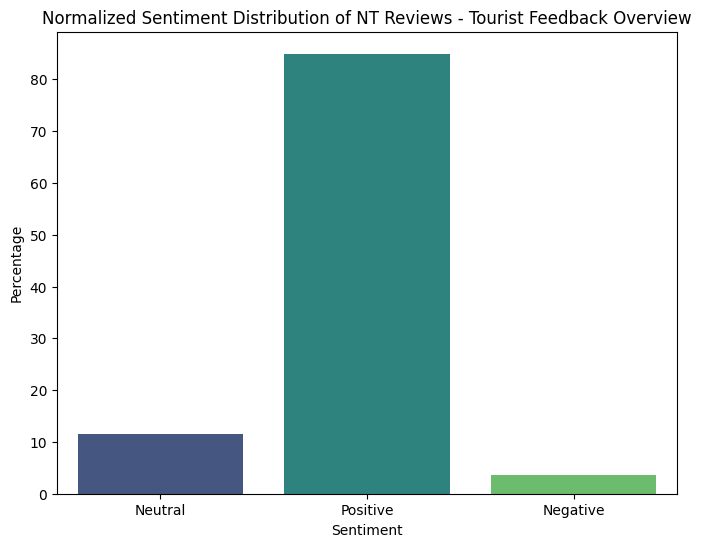

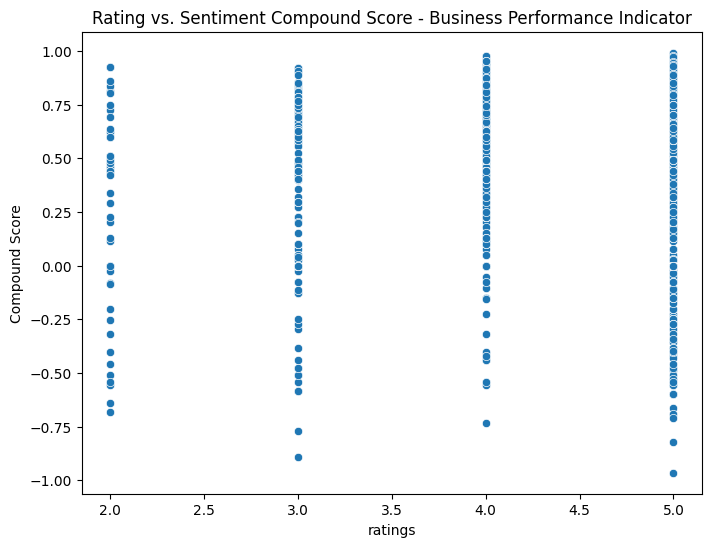

Average Compound Score (Overall Satisfaction): 0.5602051234892275

Top words related to Positive sentiments (Overall):
[('place', 917), ('great', 690), ('beautiful', 660), ('water', 454), ('walk', 352), ('amazing', 351), ('park', 341), ('visit', 328), ('pool', 302), ('nice', 296), ('good', 260), ('day', 253), ('spring', 252), ('spot', 247), ('area', 247), ('rock', 243), ('swim', 231), ('worth', 229), ('see', 226), ('swimming', 199)]

Top words related to Negative sentiments (Overall):
[('place', 25), ('park', 17), ('closed', 16), ('visit', 16), ('people', 11), ('time', 11), ('rock', 11), ('fall', 11), ('bad', 10), ('walk', 10), ('bit', 9), ('pool', 9), ('dont', 9), ('one', 9), ('worth', 9), ('go', 9), ('day', 9), ('season', 8), ('see', 8), ('lot', 8)]

Top words related to Neutral sentiments (Overall):
[('place', 55), ('must', 53), ('see', 45), ('rock', 39), ('visit', 33), ('park', 21), ('go', 18), ('uluru', 18), ('experience', 18), ('spring', 17), ('magical', 16), ('closed', 15), ('lo

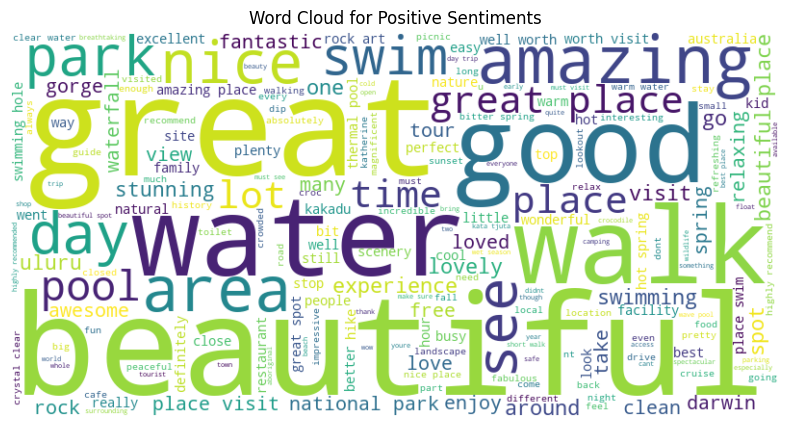

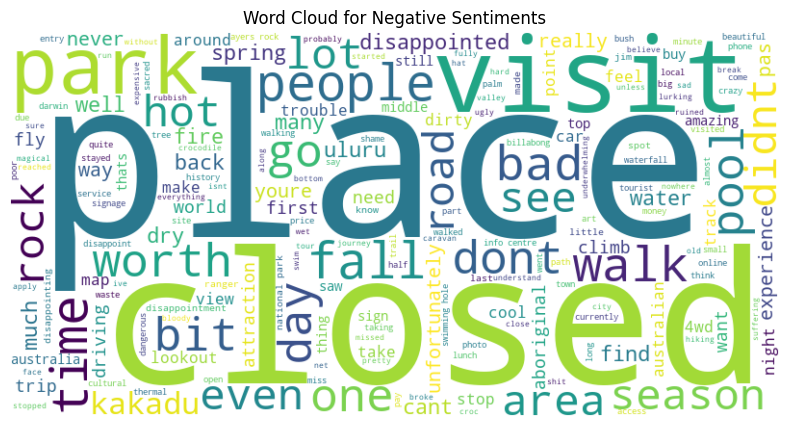

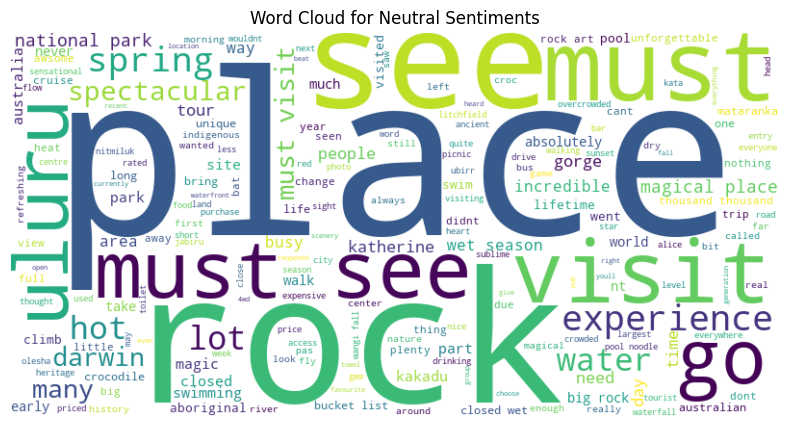


Sentiment Analysis Grouped by Region:
Average Compound Score by Region:
 region
Darwin Region          0.623198
Katherin               0.596922
Kakadu Regional        0.499280
Alice Spring Region    0.487321
Name: Compound Score, dtype: float64
Sentiment Proportions (%) by Region:
 Sentiment            Negative    Neutral   Positive
region                                             
Alice Spring Region  4.499541  17.539027  77.961433
Darwin Region        1.747573   7.961165  90.291262
Kakadu Regional      7.201646  12.757202  80.041152
Katherin             2.747710   8.576187  88.676103


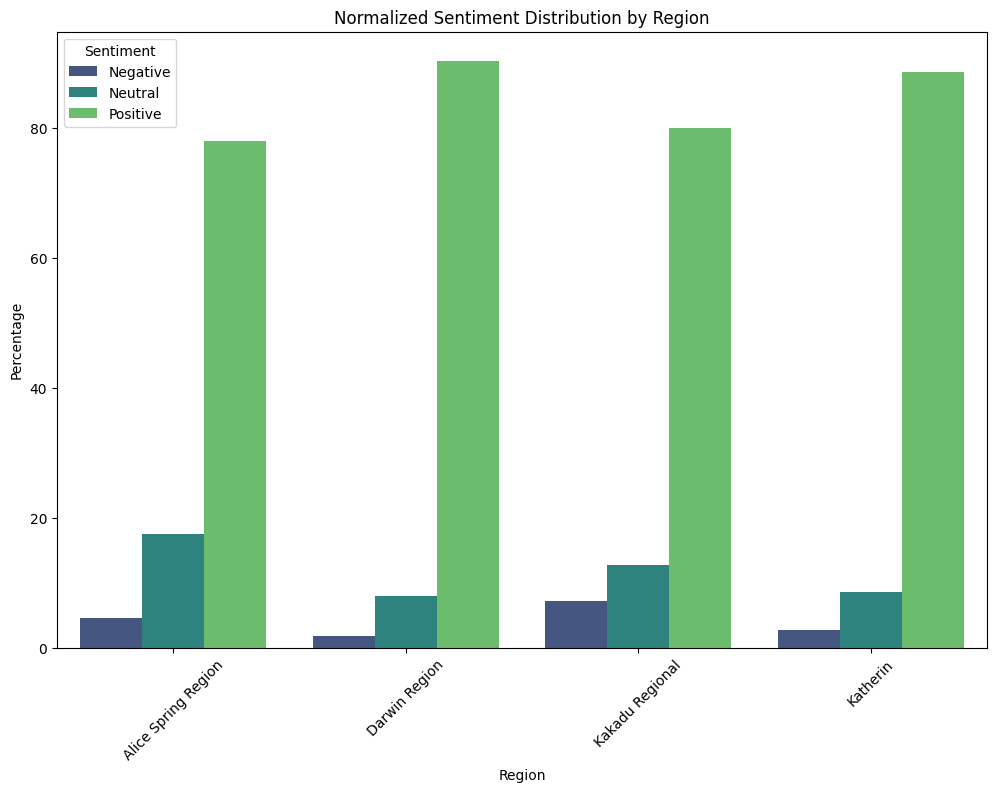

Average Rating by Region:
 region
Alice Spring Region    4.821905
Darwin Region          4.771178
Kakadu Regional        4.629067
Katherin               4.623399
Name: ratings, dtype: float64


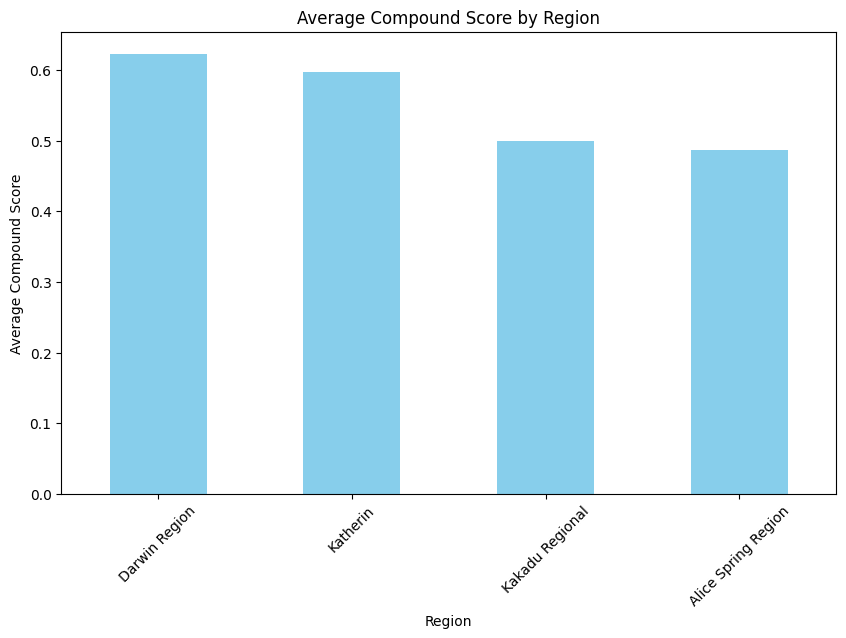


Top words for Darwin Region:
Positive: [('place', 313), ('great', 243), ('beautiful', 215), ('water', 160), ('swimming', 144), ('swim', 133), ('park', 133), ('pool', 130), ('area', 124), ('darwin', 100)]
Negative: [('people', 3), ('time', 3), ('make', 3), ('bad', 2), ('season', 2), ('darwin', 2), ('water', 2), ('waterfall', 2), ('old', 2), ('lot', 2)]
Neutral: [('place', 12), ('must', 9), ('darwin', 8), ('visit', 7), ('lot', 7), ('swimming', 6), ('go', 5), ('many', 5), ('water', 5), ('fall', 5)]

Top words for Alice Spring Region:
Positive: [('place', 219), ('beautiful', 158), ('amazing', 141), ('walk', 134), ('uluru', 123), ('rock', 122), ('great', 115), ('visit', 109), ('worth', 86), ('see', 84)]
Negative: [('place', 10), ('rock', 9), ('uluru', 7), ('people', 6), ('get', 5), ('fly', 5), ('climb', 5), ('day', 5), ('world', 4), ('one', 4)]
Neutral: [('place', 28), ('rock', 27), ('must', 22), ('see', 20), ('uluru', 18), ('visit', 12), ('big', 12), ('magical', 12), ('spectacular', 9), (

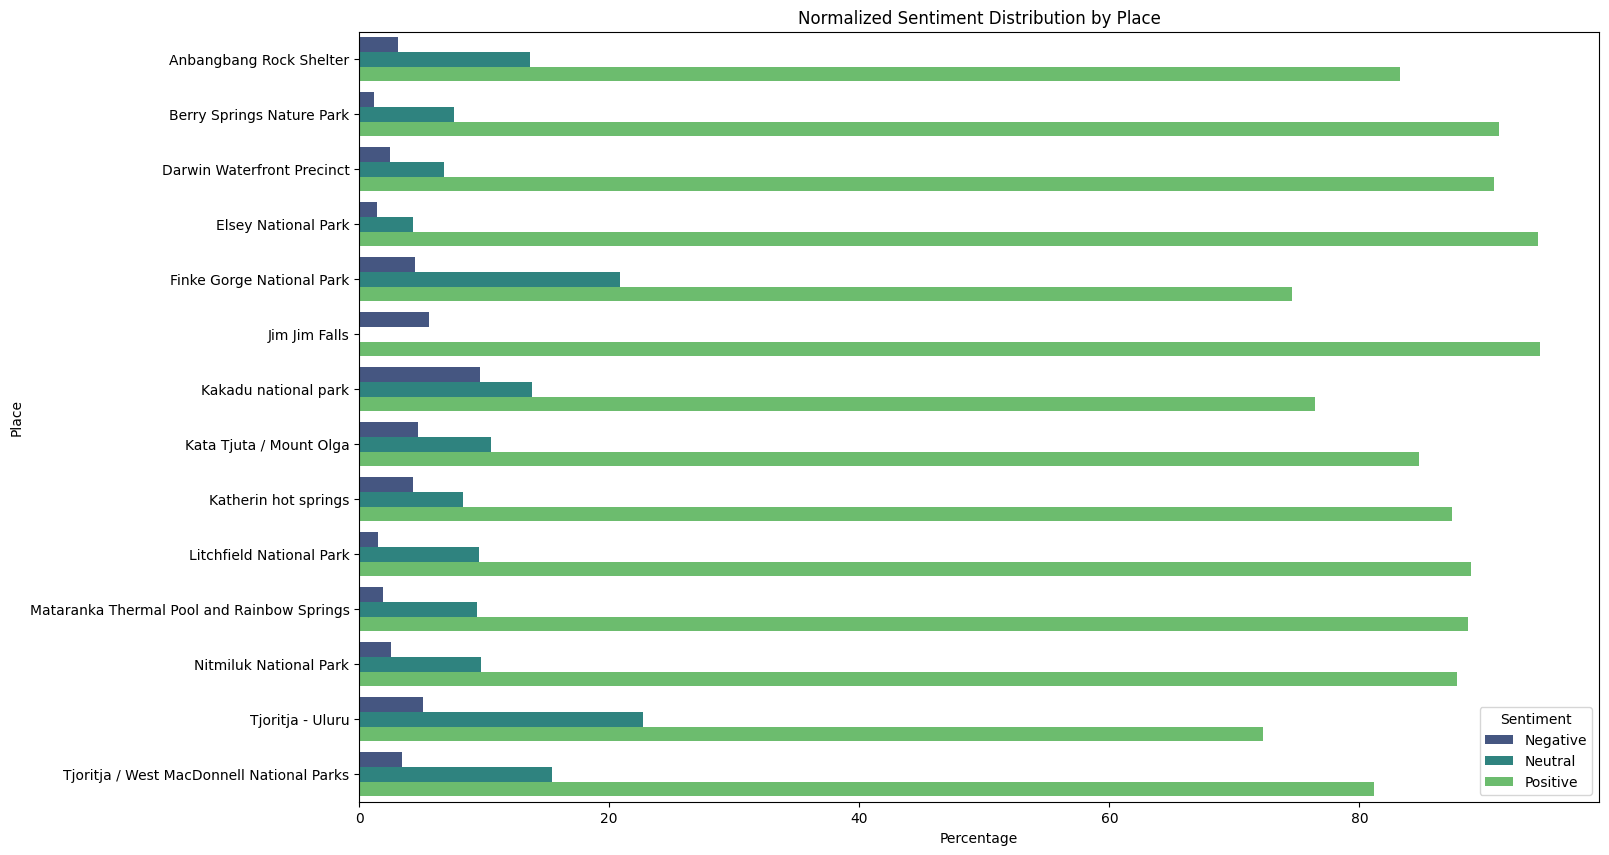

Average Rating by Place:
 name_of_place
Kata Tjuta / Mount Olga                       4.908759
Jim Jim Falls                                 4.888889
Tjoritja - Uluru                              4.846698
Litchfield National Park                      4.844776
Berry Springs Nature Park                     4.761468
Tjoritja / West MacDonnell National Parks     4.730769
Nitmiluk National Park                        4.718354
Darwin Waterfront Precinct                    4.712329
Elsey National Park                           4.705882
Anbangbang Rock Shelter                       4.701863
Finke Gorge National Park                     4.696970
Mataranka Thermal Pool and Rainbow Springs    4.568681
Katherin hot springs                          4.563380
Kakadu national park                          4.549242
Name: ratings, dtype: float64


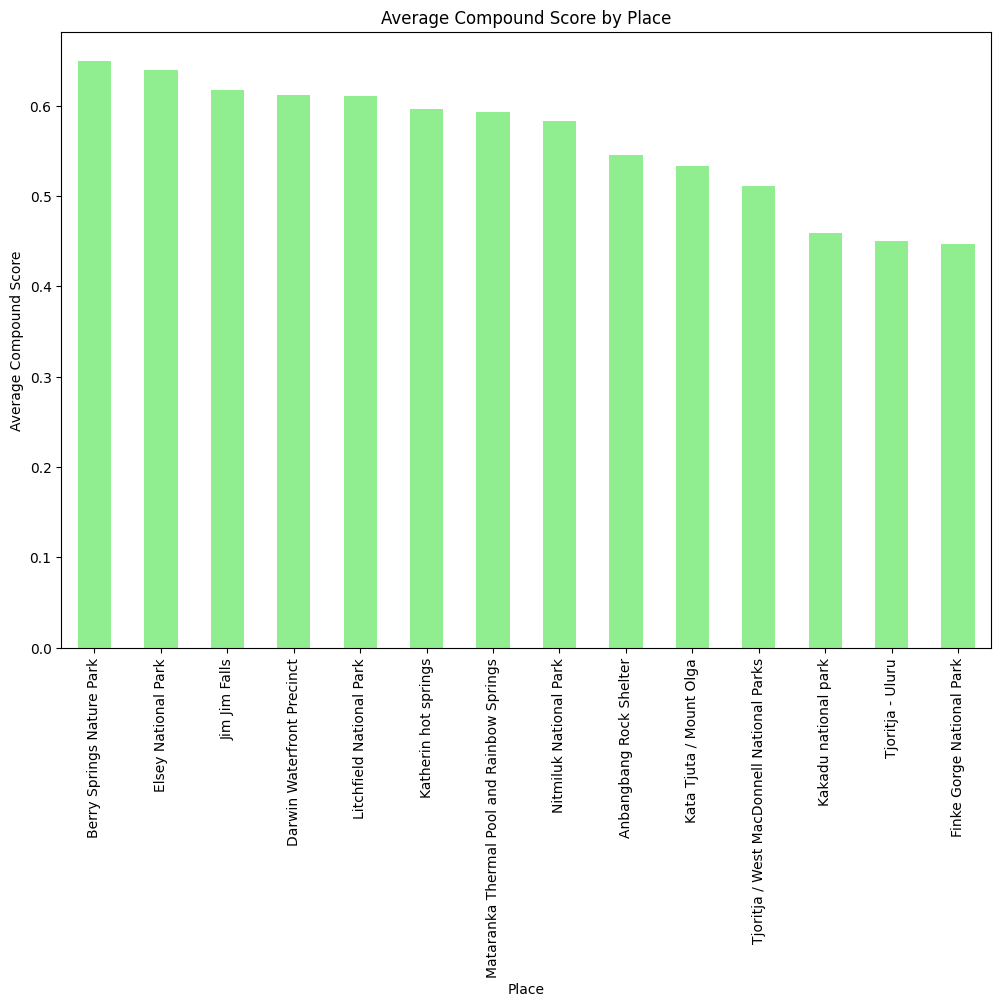


Top words for Anbangbang Rock Shelter:
Positive: [('rock', 62), ('art', 57), ('place', 36), ('walk', 33), ('great', 30), ('amazing', 27), ('beautiful', 22), ('see', 20), ('painting', 19), ('easy', 18)]
Negative: [('cool', 2), ('round', 1), ('trip', 1), ('walk', 1), ('soak', 1), ('ancient', 1), ('history', 1), ('art', 1), ('work', 1), ('nice', 1)]
Neutral: [('rock', 5), ('visit', 4), ('art', 4), ('must', 4), ('site', 3), ('history', 3), ('ubirr', 2), ('tribe', 2), ('view', 2), ('indigenous', 2)]

Top words for Berry Springs Nature Park:
Positive: [('water', 105), ('place', 101), ('beautiful', 96), ('pool', 74), ('swim', 71), ('swimming', 59), ('great', 52), ('spot', 52), ('spring', 52), ('area', 40)]
Negative: [('people', 2), ('bad', 1), ('isnt', 1), ('600', 1), ('bit', 1), ('disappointed', 1), ('swimming', 1), ('hole', 1), ('walking', 1), ('track', 1)]
Neutral: [('must', 3), ('visit', 3), ('get', 3), ('pool', 3), ('closed', 3), ('go', 2), ('place', 2), ('still', 2), ('star', 2), ('peo

In [1]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import string
from gensim import corpora
from gensim.models import LdaModel
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns
import re
from collections import Counter
import os

os.makedirs('Output/google_sentiment_analysis_output', exist_ok=True)

# Download NLTK resources (run once)
nltk.download('vader_lexicon', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

# Load the CSV file from the specified path
file_path = 'Google_review_data_combined.csv'
df = pd.read_csv(file_path)

# Convert ratings to numeric
df['ratings'] = pd.to_numeric(df['ratings'], errors='coerce')

print("Data loaded successfully. Shape:", df.shape)
print(df.head())

# Classify and show each region and name of the place
print("\nClassified Regions and Places:")
unique_regions = df['region'].unique()
for region in sorted(unique_regions):
    print(f"Region: {region}")
    places = df[df['region'] == region]['name_of_place'].unique()
    for place in sorted(places):
        print(f"  - {place}")

# Data Preprocessing
def preprocess_text(text):
    if not isinstance(text, str):
        return ''
    text = re.sub(r'[^\w\s]', '', text)
    text = text.lower()
    tokens = word_tokenize(text)
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words and word not in string.punctuation]
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return ' '.join(tokens)

df['Processed Review'] = df['reviews'].apply(preprocess_text)

# Part 1: Advanced Sentiment Analysis using VADER for Business Feedback
sia = SentimentIntensityAnalyzer()

def get_sentiment(text):
    scores = sia.polarity_scores(text)
    if scores['compound'] >= 0.05:
        return 'Positive'
    elif scores['compound'] <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment'] = df['Processed Review'].apply(get_sentiment)
df['Compound Score'] = df['Processed Review'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Overall visualizations
# Visualize Sentiment Distribution - Key for identifying overall tourist satisfaction (normalized)
plt.figure(figsize=(8, 6))
sns.countplot(x='Sentiment', data=df, palette='viridis', stat='percent')
plt.title('Normalized Sentiment Distribution of NT Reviews - Tourist Feedback Overview')
plt.xlabel('Sentiment')
plt.ylabel('Percentage')
plt.show()

# Correlation between Rating and Compound Score - Helps correlate feedback with business ratings
plt.figure(figsize=(8, 6))
sns.scatterplot(x='ratings', y='Compound Score', data=df)
plt.title('Rating vs. Sentiment Compound Score - Business Performance Indicator')
plt.show()

print("Average Compound Score (Overall Satisfaction):", df['Compound Score'].mean())

# Insightful analysis: Top words related to each sentiment (overall)
def get_top_words(sentiment_df, n=20):
    all_text = ' '.join(sentiment_df['Processed Review'])
    words = all_text.split()
    word_counts = Counter(words)
    return word_counts.most_common(n)

positive_df = df[df['Sentiment'] == 'Positive']
negative_df = df[df['Sentiment'] == 'Negative']
neutral_df = df[df['Sentiment'] == 'Neutral']

print("\nTop words related to Positive sentiments (Overall):")
print(get_top_words(positive_df))

print("\nTop words related to Negative sentiments (Overall):")
print(get_top_words(negative_df))

print("\nTop words related to Neutral sentiments (Overall):")
print(get_top_words(neutral_df))

# Word clouds for sentiments
def generate_wordcloud(text, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title)
    plt.axis('off')
    plt.show()

generate_wordcloud(' '.join(positive_df['Processed Review']), 'Word Cloud for Positive Sentiments')
generate_wordcloud(' '.join(negative_df['Processed Review']), 'Word Cloud for Negative Sentiments')
generate_wordcloud(' '.join(neutral_df['Processed Review']), 'Word Cloud for Neutral Sentiments')

# Group by region
print("\nSentiment Analysis Grouped by Region:")

# Average Compound Score by Region
avg_score_region = df.groupby('region')['Compound Score'].mean().sort_values(ascending=False)
print("Average Compound Score by Region:\n", avg_score_region)

# Sentiment Proportions by Region
sentiment_counts_region = df.groupby(['region', 'Sentiment']).size().unstack(fill_value=0)
sentiment_proportions_region = sentiment_counts_region.div(sentiment_counts_region.sum(axis=1), axis=0) * 100
print("Sentiment Proportions (%) by Region:\n", sentiment_proportions_region)

# Visualize Normalized Sentiment Distribution by Region (using barplot for proper per-group normalization)
sentiment_proportions_region_reset = sentiment_proportions_region.reset_index().melt(id_vars='region', var_name='Sentiment', value_name='Percentage')
plt.figure(figsize=(12, 8))
sns.barplot(x='region', y='Percentage', hue='Sentiment', data=sentiment_proportions_region_reset, palette='viridis')
plt.title('Normalized Sentiment Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Percentage')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.show()

# Average Rating by Region
avg_rating_region = df.groupby('region')['ratings'].mean().sort_values(ascending=False)
print("Average Rating by Region:\n", avg_rating_region)

# Visualize Average Compound Score by Region
plt.figure(figsize=(10, 6))
avg_score_region.plot(kind='bar', color='skyblue')
plt.title('Average Compound Score by Region')
plt.xlabel('Region')
plt.ylabel('Average Compound Score')
plt.xticks(rotation=45)
plt.show()

# Insightful analysis: Top words by sentiment for each region
for region in unique_regions:
    region_df = df[df['region'] == region]
    positive_region = region_df[region_df['Sentiment'] == 'Positive']
    negative_region = region_df[region_df['Sentiment'] == 'Negative']
    neutral_region = region_df[region_df['Sentiment'] == 'Neutral']
    
    print(f"\nTop words for {region}:")
    print("Positive:", get_top_words(positive_region, n=10))
    print("Negative:", get_top_words(negative_region, n=10))
    print("Neutral:", get_top_words(neutral_region, n=10))

# Group by places (name_of_place)
print("\nSentiment Analysis Grouped by Places:")

# Average Compound Score by Place
avg_score_place = df.groupby('name_of_place')['Compound Score'].mean().sort_values(ascending=False)
print("Average Compound Score by Place:\n", avg_score_place)

# Sentiment Proportions by Place
sentiment_counts_place = df.groupby(['name_of_place', 'Sentiment']).size().unstack(fill_value=0)
sentiment_proportions_place = sentiment_counts_place.div(sentiment_counts_place.sum(axis=1), axis=0) * 100
print("Sentiment Proportions (%) by Place:\n", sentiment_proportions_place)

# Visualize Normalized Sentiment Distribution by Place (using barplot for proper per-group normalization)
sentiment_proportions_place_reset = sentiment_proportions_place.reset_index().melt(id_vars='name_of_place', var_name='Sentiment', value_name='Percentage')
plt.figure(figsize=(16, 10))
sns.barplot(y='name_of_place', x='Percentage', hue='Sentiment', data=sentiment_proportions_place_reset, palette='viridis', orient='h')
plt.title('Normalized Sentiment Distribution by Place')
plt.xlabel('Percentage')
plt.ylabel('Place')
plt.legend(title='Sentiment')
plt.show()

# Average Rating by Place
avg_rating_place = df.groupby('name_of_place')['ratings'].mean().sort_values(ascending=False)
print("Average Rating by Place:\n", avg_rating_place)

# Visualize Average Compound Score by Place
plt.figure(figsize=(12, 8))
avg_score_place.plot(kind='bar', color='lightgreen')
plt.title('Average Compound Score by Place')
plt.xlabel('Place')
plt.ylabel('Average Compound Score')
plt.xticks(rotation=90)
plt.show()

# Insightful analysis: Top words by sentiment for each place
unique_places = df['name_of_place'].unique()
for place in sorted(unique_places):
    place_df = df[df['name_of_place'] == place]
    positive_place = place_df[place_df['Sentiment'] == 'Positive']
    negative_place = place_df[place_df['Sentiment'] == 'Negative']
    neutral_place = place_df[place_df['Sentiment'] == 'Neutral']
    
    print(f"\nTop words for {place}:")
    print("Positive:", get_top_words(positive_place, n=10))
    print("Negative:", get_top_words(negative_place, n=10))
    print("Neutral:", get_top_words(neutral_place, n=10))




# Create Output directory if it doesn't exist
os.makedirs('Output', exist_ok=True)

# Export statistics to file
output_file = 'Output/google_sentiment_analysis_output.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write("Google Review Sentiment Analysis Statistics\n")
    f.write("=" * 50 + "\n\n")
    
    f.write("Data Summary:\n")
    f.write(f"Total Reviews: {df.shape[0]}\n")
    f.write(f"Average Compound Score (Overall Satisfaction): {df['Compound Score'].mean():.4f}\n\n")
    
    f.write("Classified Regions and Places:\n")
    unique_regions = df['region'].unique()
    for region in sorted(unique_regions):
        f.write(f"Region: {region}\n")
        places = df[df['region'] == region]['name_of_place'].unique()
        for place in sorted(places):
            f.write(f"  - {place}\n")
    f.write("\n")
    
    f.write("Sentiment Distribution (Overall):\n")
    sentiment_counts = df['Sentiment'].value_counts(normalize=True) * 100
    for sentiment, percentage in sentiment_counts.items():
        f.write(f"{sentiment}: {percentage:.2f}%\n")
    f.write("\n")
    
    f.write("Top Words by Sentiment (Overall):\n")
    f.write("Positive:\n")
    for word, count in get_top_words(positive_df):
        f.write(f"  {word}: {count}\n")
    f.write("\nNegative:\n")
    for word, count in get_top_words(negative_df):
        f.write(f"  {word}: {count}\n")
    f.write("\nNeutral:\n")
    for word, count in get_top_words(neutral_df):
        f.write(f"  {word}: {count}\n")
    f.write("\n")
    
    f.write("Sentiment Analysis by Region:\n")
    avg_score_region = df.groupby('region')['Compound Score'].mean().sort_values(ascending=False)
    f.write("Average Compound Score by Region:\n")
    for region, score in avg_score_region.items():
        f.write(f"{region}: {score:.4f}\n")
    f.write("\n")
    
    sentiment_counts_region = df.groupby(['region', 'Sentiment']).size().unstack(fill_value=0)
    sentiment_proportions_region = sentiment_counts_region.div(sentiment_counts_region.sum(axis=1), axis=0) * 100
    f.write("Sentiment Proportions (%) by Region:\n")
    for region in sentiment_proportions_region.index:
        f.write(f"{region}:\n")
        for sentiment in sentiment_proportions_region.columns:
            f.write(f"  {sentiment}: {sentiment_proportions_region.loc[region, sentiment]:.2f}%\n")
    f.write("\n")
    
    avg_rating_region = df.groupby('region')['ratings'].mean().sort_values(ascending=False)
    f.write("Average Rating by Region:\n")
    for region, rating in avg_rating_region.items():
        f.write(f"{region}: {rating:.4f}\n")
    f.write("\n")
    
    f.write("Top Words by Sentiment for Each Region:\n")
    for region in sorted(unique_regions):
        region_df = df[df['region'] == region]
        positive_region = region_df[region_df['Sentiment'] == 'Positive']
        negative_region = region_df[region_df['Sentiment'] == 'Negative']
        neutral_region = region_df[region_df['Sentiment'] == 'Neutral']
        f.write(f"{region}:\n")
        f.write("  Positive:\n")
        for word, count in get_top_words(positive_region, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("  Negative:\n")
        for word, count in get_top_words(negative_region, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("  Neutral:\n")
        for word, count in get_top_words(neutral_region, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("\n")
    
    f.write("Sentiment Analysis by Place:\n")
    avg_score_place = df.groupby('name_of_place')['Compound Score'].mean().sort_values(ascending=False)
    f.write("Average Compound Score by Place:\n")
    for place, score in avg_score_place.items():
        f.write(f"{place}: {score:.4f}\n")
    f.write("\n")
    
    sentiment_counts_place = df.groupby(['name_of_place', 'Sentiment']).size().unstack(fill_value=0)
    sentiment_proportions_place = sentiment_counts_place.div(sentiment_counts_place.sum(axis=1), axis=0) * 100
    f.write("Sentiment Proportions (%) by Place:\n")
    for place in sentiment_proportions_place.index:
        f.write(f"{place}:\n")
        for sentiment in sentiment_proportions_place.columns:
            f.write(f"  {sentiment}: {sentiment_proportions_place.loc[place, sentiment]:.2f}%\n")
    f.write("\n")
    
    avg_rating_place = df.groupby('name_of_place')['ratings'].mean().sort_values(ascending=False)
    f.write("Average Rating by Place:\n")
    for place, rating in avg_rating_place.items():
        f.write(f"{place}: {rating:.4f}\n")
    f.write("\n")
    
    f.write("Top Words by Sentiment for Each Place:\n")
    unique_places = df['name_of_place'].unique()
    for place in sorted(unique_places):
        place_df = df[df['name_of_place'] == place]
        positive_place = place_df[place_df['Sentiment'] == 'Positive']
        negative_place = place_df[place_df['Sentiment'] == 'Negative']
        neutral_place = place_df[place_df['Sentiment'] == 'Neutral']
        f.write(f"{place}:\n")
        f.write("  Positive:\n")
        for word, count in get_top_words(positive_place, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("  Negative:\n")
        for word, count in get_top_words(negative_place, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("  Neutral:\n")
        for word, count in get_top_words(neutral_place, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("\n")

print(f"Statistics exported to {output_file}")

Dominant Topics Table (Overall):
   Topic                                          Top Terms
0      0  beautiful, place, park, great, nature, visit, ...
1      1  rock, see, amazing, place, park, must, art, go...
2      2  water, place, spring, great, nice, warm, swim,...
3      3  great, place, pool, visit, good, water, area, ...
4      4  day, walk, worth, well, beautiful, tour, fall,...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Dominant Topic', data=df, palette='viridis', stat='percent')


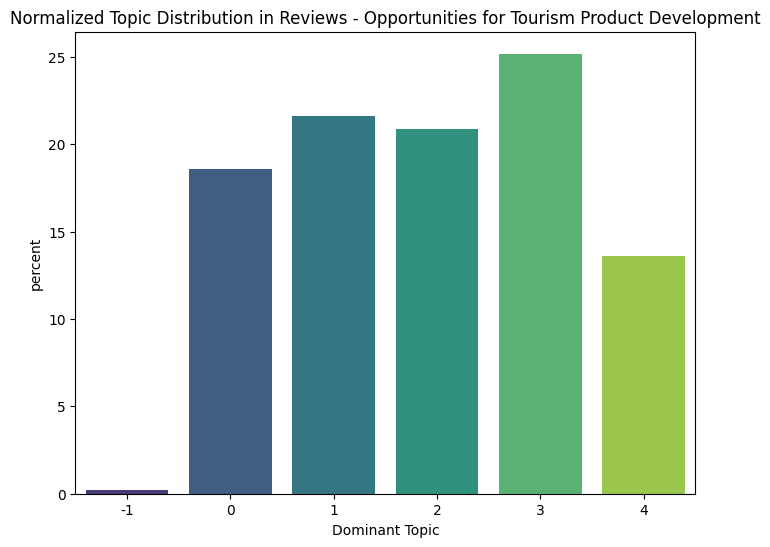

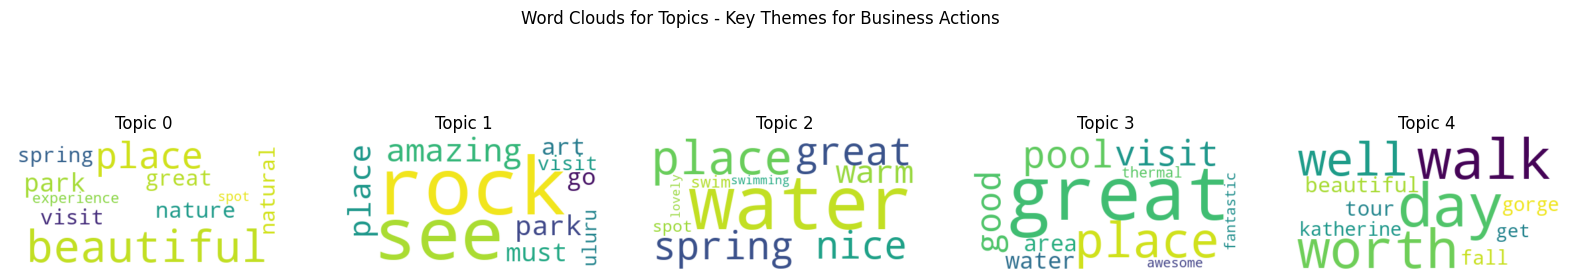


Topic Analysis Grouped by Region:

Region: Darwin Region
Dominant Topics Table for Darwin Region:
   Topic                                          Top Terms
0      0  place, great, swim, swimming, beautiful, water...
1      1  beautiful, place, water, great, worth, swimmin...
2      2  park, place, amazing, visit, fall, day, get, n...
3      3  park, water, plenty, free, nature, well, berry...
4      4  great, pool, area, restaurant, beautiful, nice...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Region Dominant Topic', data=region_df, palette='viridis', stat='percent')


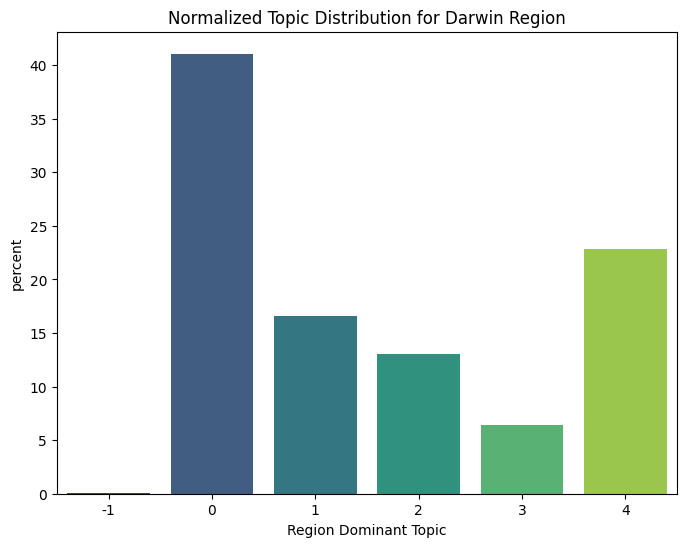

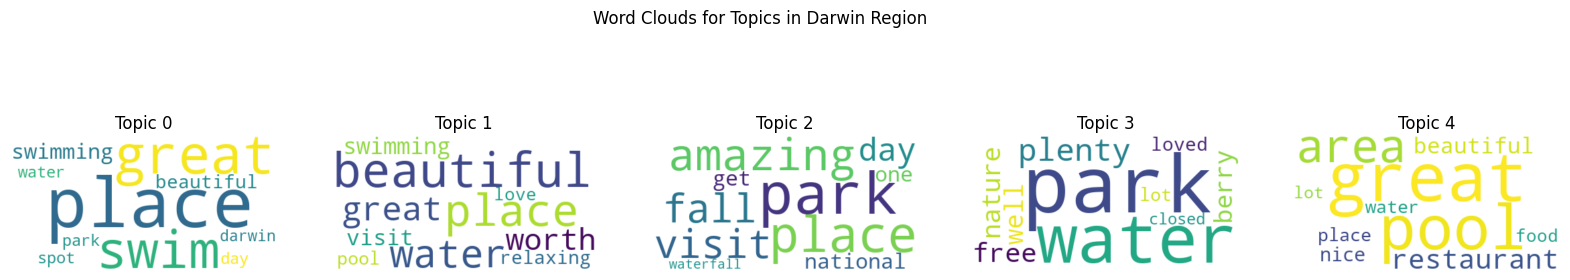


Region: Alice Spring Region
Dominant Topics Table for Alice Spring Region:
   Topic                                          Top Terms
0      0  walk, place, beautiful, gorge, uluru, stunning...
1      1  beautiful, place, amazing, experience, see, sc...
2      2  rock, uluru, australia, experience, breathtaki...
3      3  place, uluru, visit, see, must, rock, around, ...
4      4  walk, place, great, visit, amazing, rock, wort...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Region Dominant Topic', data=region_df, palette='viridis', stat='percent')


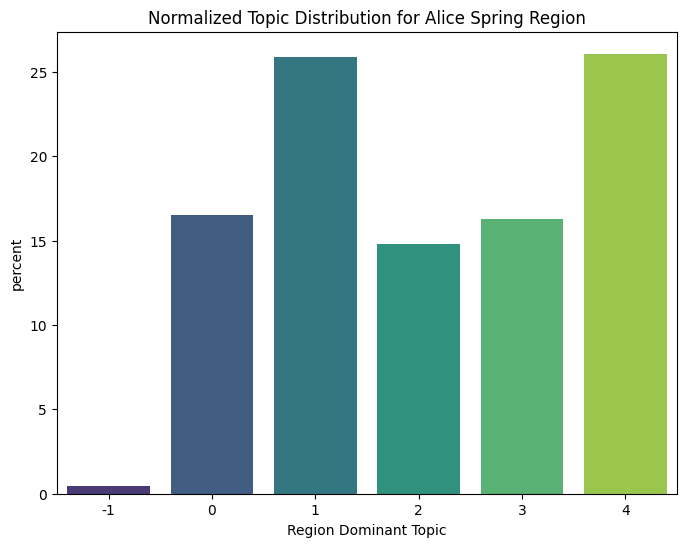

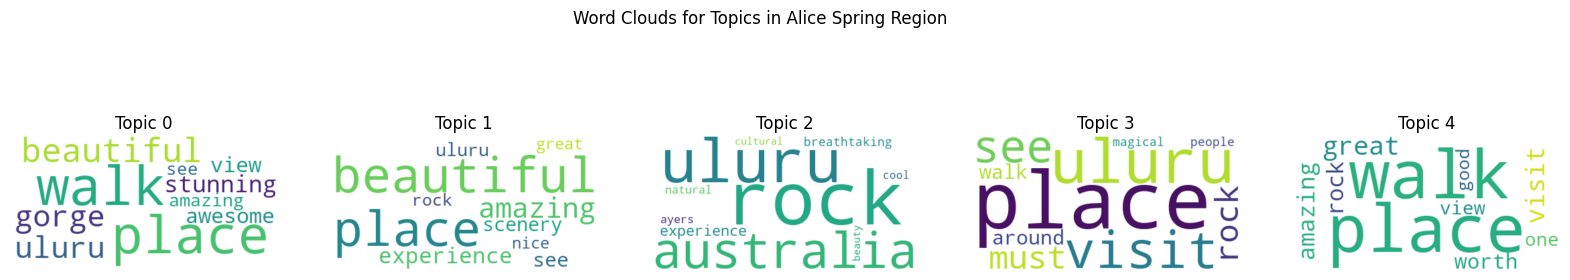


Region: Kakadu Regional
Dominant Topics Table for Kakadu Regional:
   Topic                                          Top Terms
0      0  place, see, good, park, great, lot, water, roc...
1      1  rock, art, day, see, park, kakadu, beautiful, ...
2      2  rock, beautiful, walk, art, great, park, place...
3      3  fall, jim, see, park, kakadu, place, never, go...
4      4  place, visit, beautiful, amazing, kakadu, grea...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Region Dominant Topic', data=region_df, palette='viridis', stat='percent')


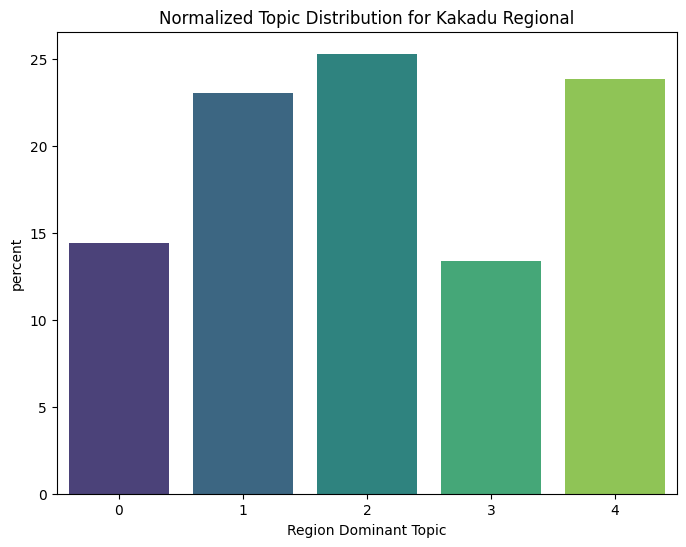

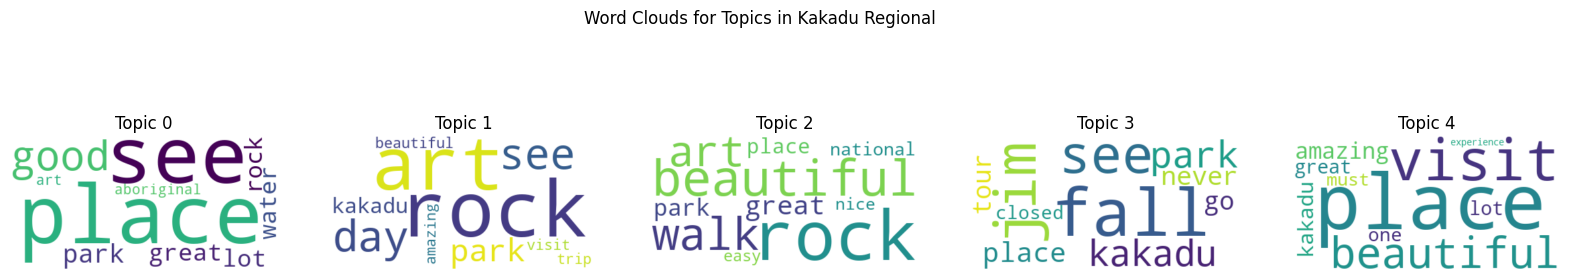


Region: Katherin
Dominant Topics Table for Katherin:
   Topic                                          Top Terms
0      0  park, great, gorge, walk, pool, water, thermal...
1      1  good, place, water, hot, spring, pool, great, ...
2      2  nice, place, spring, water, park, town, little...
3      3  great, place, spot, visit, pool, beautiful, sw...
4      4  water, beautiful, spring, warm, place, amazing...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Region Dominant Topic', data=region_df, palette='viridis', stat='percent')


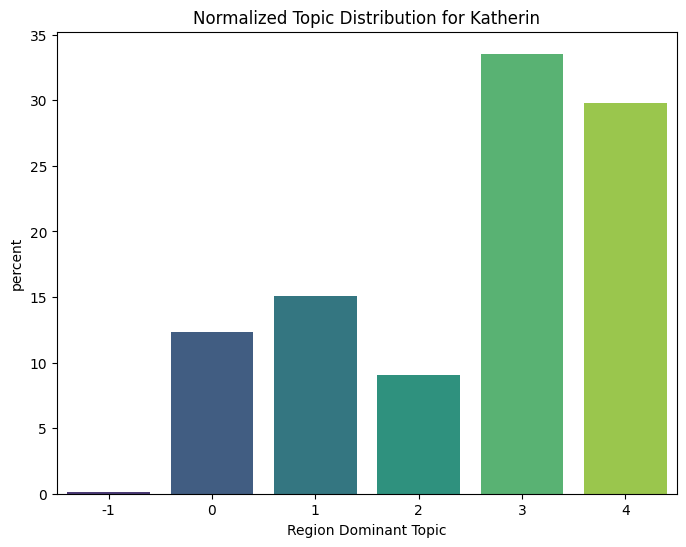

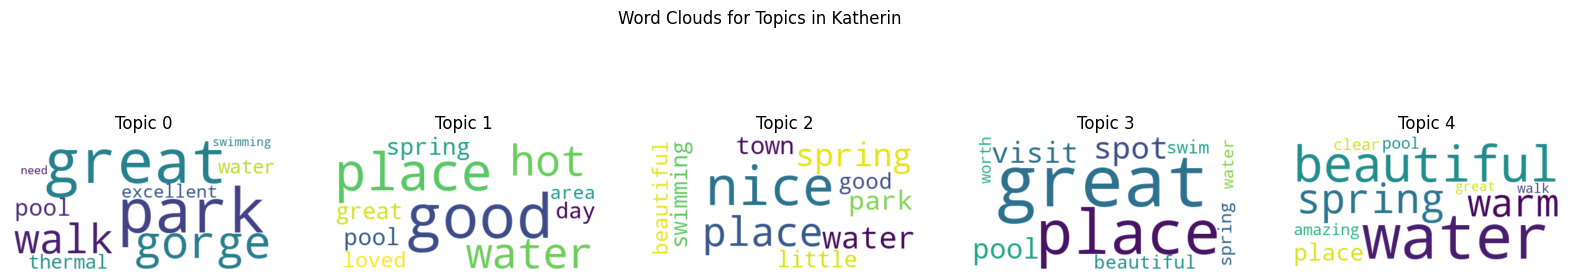


Topic Analysis Grouped by Place:

Place: Berry Springs Nature Park
Dominant Topics Table for Berry Springs Nature Park:
   Topic                                          Top Terms
0      0  pool, spot, swimming, darwin, swim, busy, beau...
1      1  beautiful, water, spot, pool, get, bring, nood...
2      2  beautiful, swimming, pool, water, place, close...
3      3  place, beautiful, great, swim, picnic, spot, w...
4      4  water, place, pool, spring, swim, lovely, warm...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


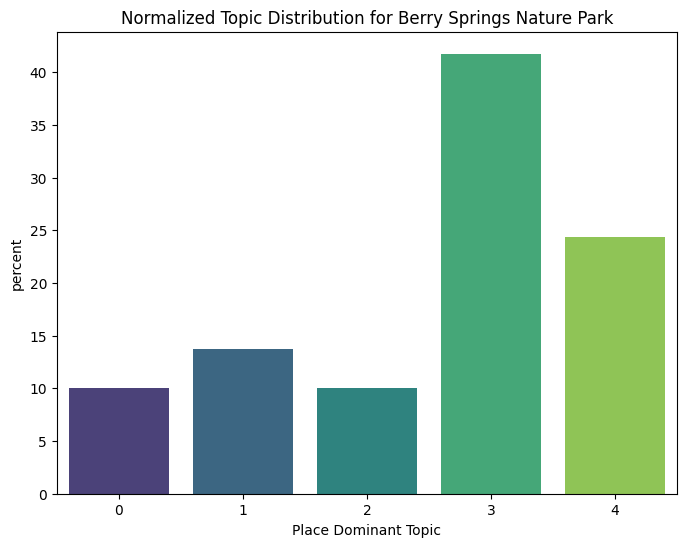

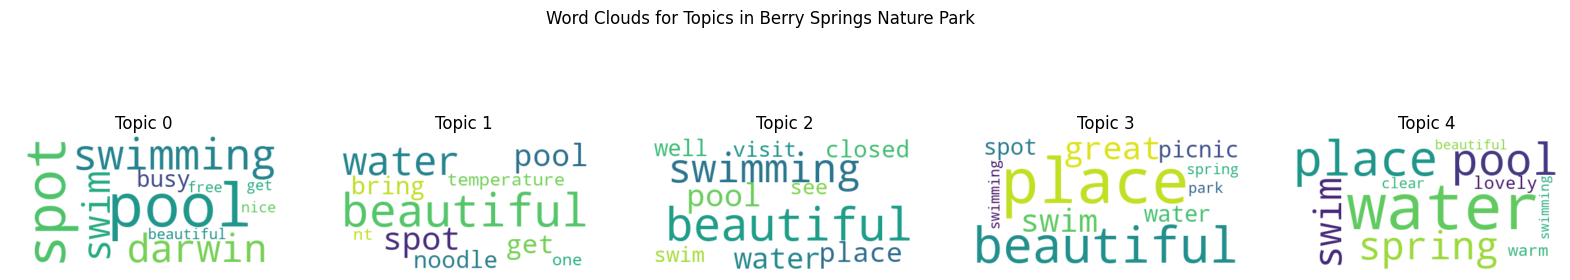


Place: Litchfield National Park
Dominant Topics Table for Litchfield National Park:
   Topic                                          Top Terms
0      0  day, beautiful, swim, fall, one, spot, darwin,...
1      1  place, park, swimming, amazing, beautiful, nat...
2      2  great, visit, place, park, fall, day, swim, wa...
3      3  beautiful, place, waterfall, park, walk, day, ...
4      4  place, waterfall, visit, great, beautiful, fal...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


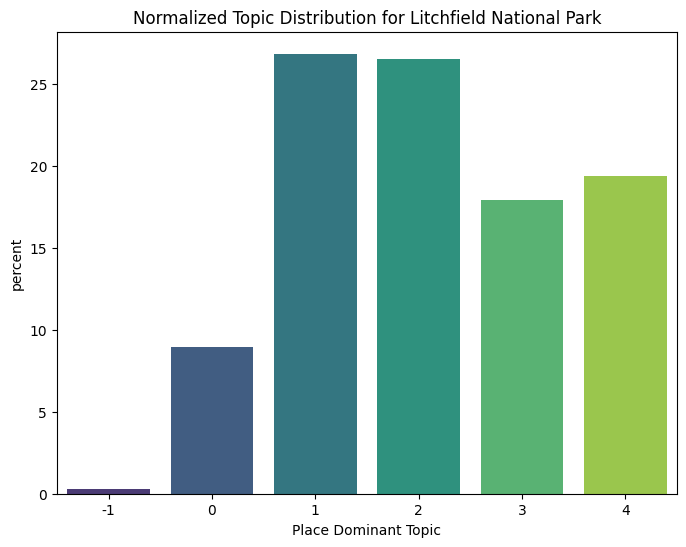

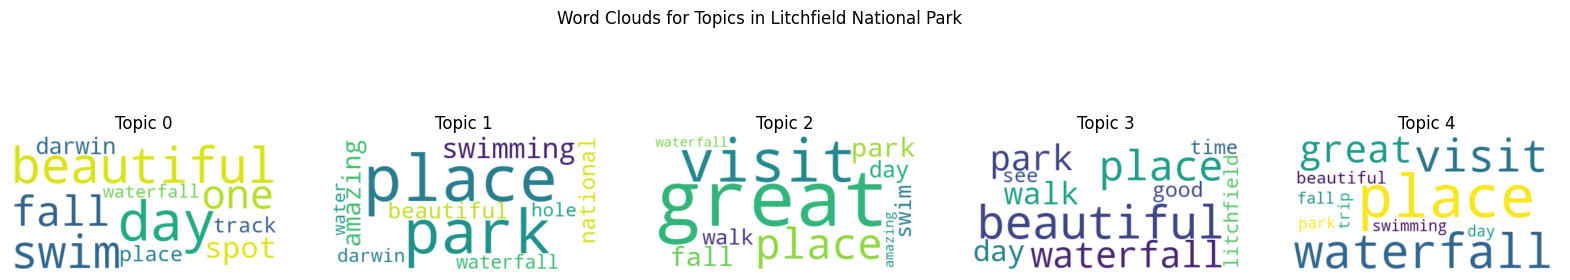


Place: Darwin Waterfront Precinct
Dominant Topics Table for Darwin Waterfront Precinct:
   Topic                                          Top Terms
0      0  great, area, food, place, good, restaurant, sw...
1      1  beautiful, nice, area, walk, plenty, view, wel...
2      2  good, great, restaurant, darwin, place, food, ...
3      3  great, place, restaurant, lot, option, visit, ...
4      4  place, great, pool, wave, area, darwin, nice, ...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


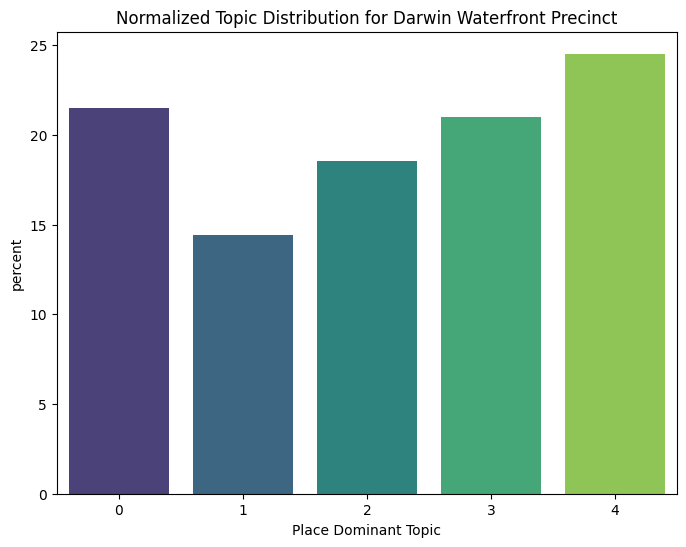

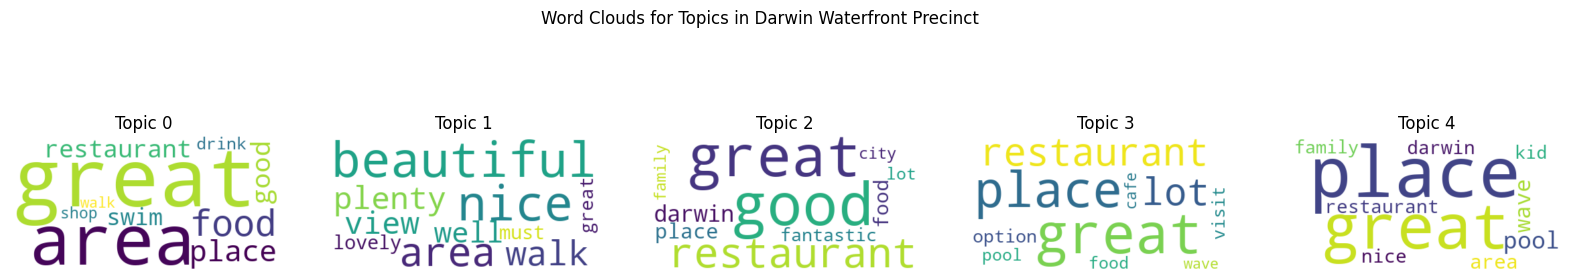


Place: Finke Gorge National Park
Dominant Topics Table for Finke Gorge National Park:
   Topic                                          Top Terms
0      0  4wd, thousand, amazing, nice, game, scenery, t...
1      1  place, drive, amazing, great, river, vehicle, ...
2      2  good, walk, wonderful, drive, get, australia, ...
3      3  beautiful, place, stunning, worth, park, tough...
4      4  track, valley, palm, beautiful, view, hello, p...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


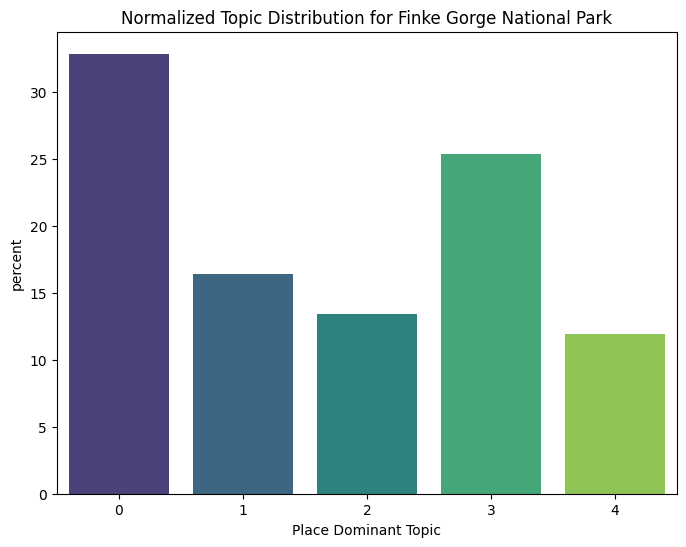

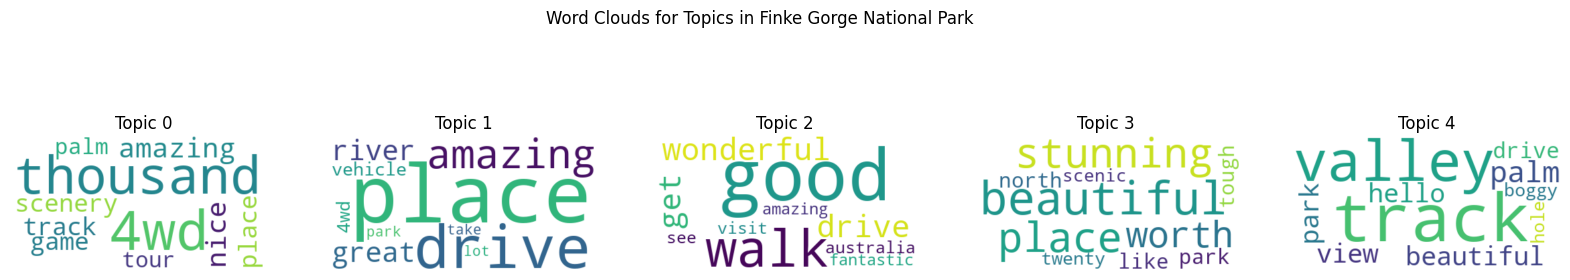


Place: Tjoritja - Uluru
Dominant Topics Table for Tjoritja - Uluru:
   Topic                                          Top Terms
0      0  rock, uluru, place, ayers, tour, visit, beauti...
1      1  rock, beautiful, see, experience, uluru, visit...
2      2  place, rock, visit, worth, magical, uluru, ama...
3      3  great, amazing, rock, top, walk, place, view, ...
4      4  uluru, place, experience, see, australia, amaz...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


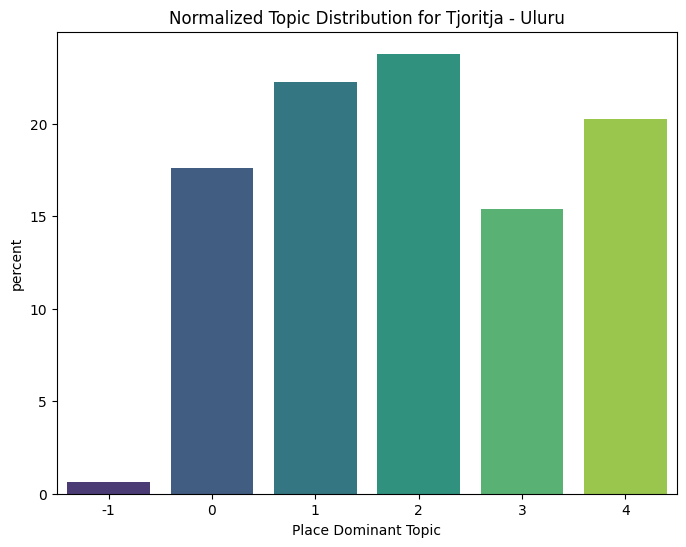

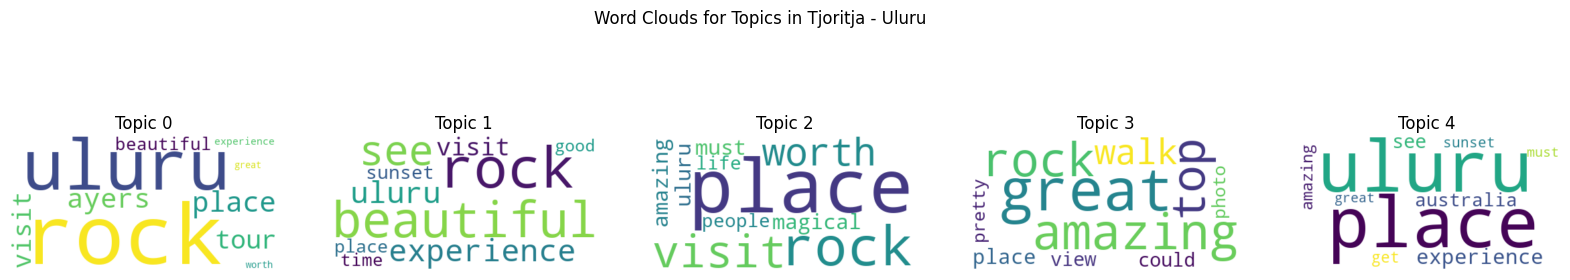


Place: Kata Tjuta / Mount Olga
Dominant Topics Table for Kata Tjuta / Mount Olga:
   Topic                                          Top Terms
0      0  place, good, rock, water, fantastic, uluru, li...
1      1  beautiful, walk, place, uluru, yo, well, wind,...
2      2  place, uluru, amazing, walk, kata, visit, one,...
3      3  rock, uluru, walk, tjuta, kata, beautiful, def...
4      4  walk, wind, valley, great, place, area, uluru,...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


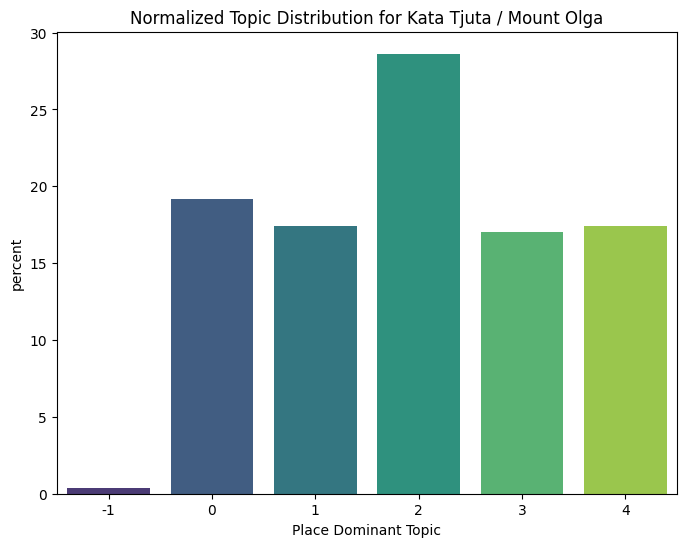

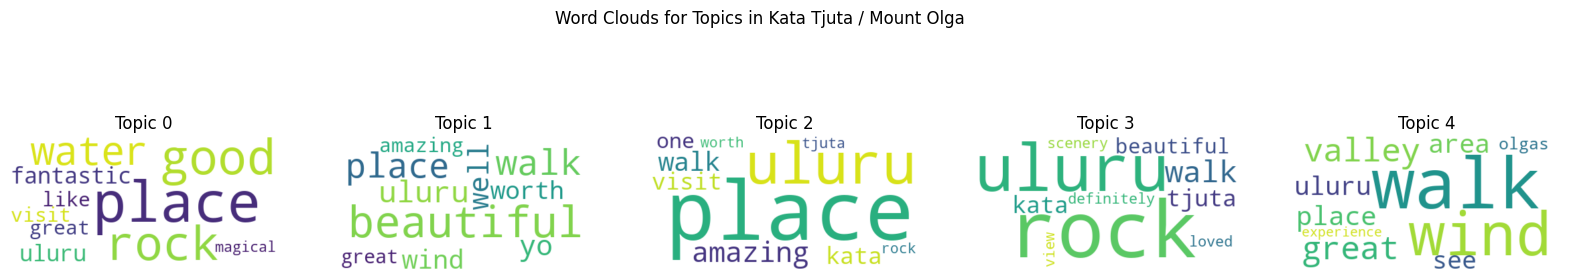


Place: Tjoritja / West MacDonnell National Parks
Dominant Topics Table for Tjoritja / West MacDonnell National Parks:
   Topic                                          Top Terms
0      0  beautiful, place, great, visit, see, walk, mus...
1      1  must, go, stunning, see, definitely, wow, driv...
2      2  gorge, day, one, gap, trip, really, cool, simp...
3      3  area, absolutely, place, good, beautiful, amaz...
4      4  amazing, place, nice, great, view, beautiful, ...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


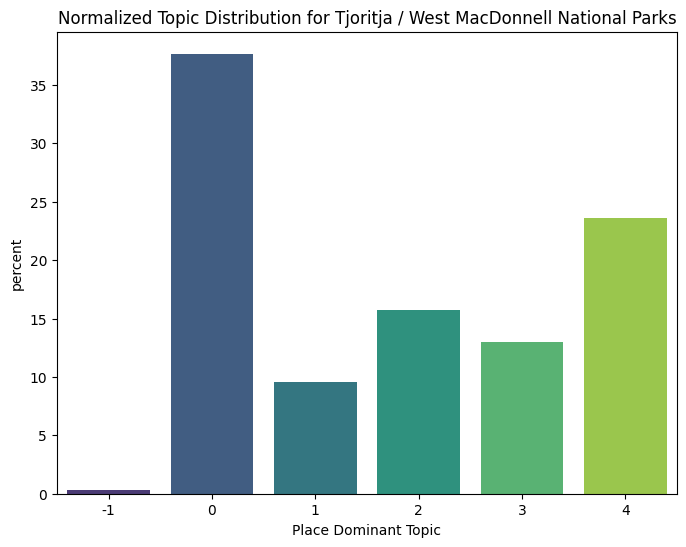

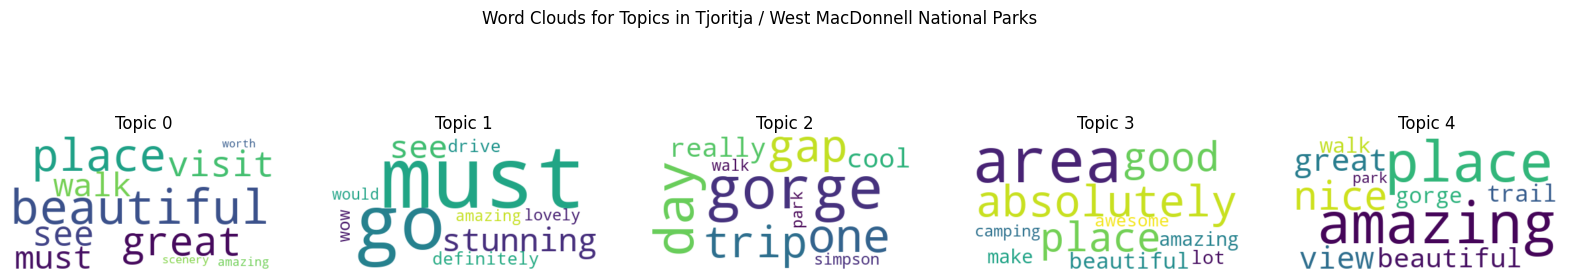


Place: Kakadu national park
Dominant Topics Table for Kakadu national park:
   Topic                                          Top Terms
0      0  place, beautiful, one, amazing, lot, best, aus...
1      1  closed, park, jim, fall, kakadu, place, go, se...
2      2  park, kakadu, rock, experience, art, national,...
3      3  see, visit, day, place, time, must, kakadu, lo...
4      4  park, national, great, rock, beautiful, place,...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


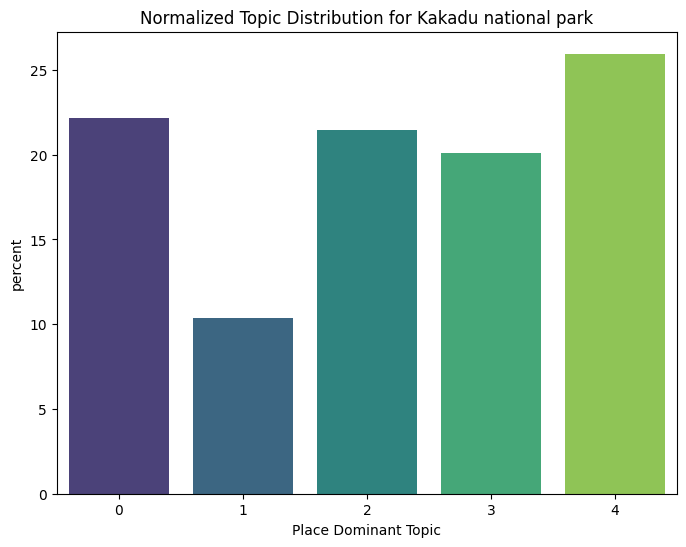

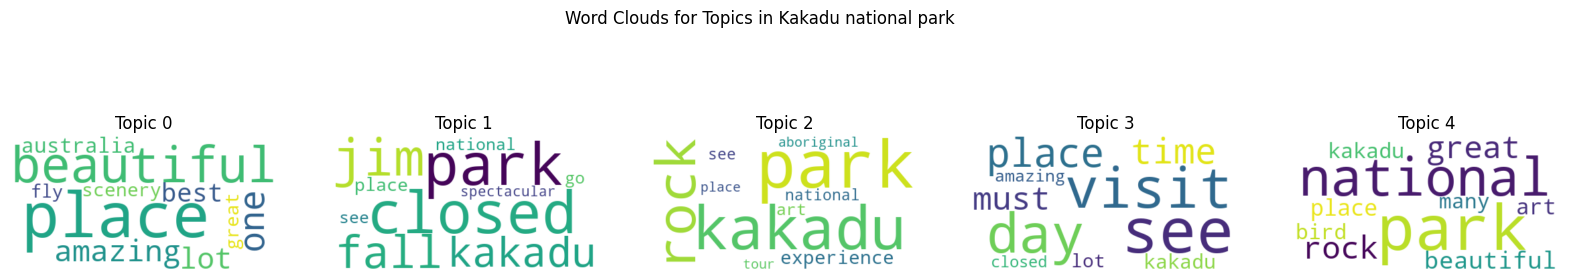


Place: Anbangbang Rock Shelter
Dominant Topics Table for Anbangbang Rock Shelter:
   Topic                                          Top Terms
0      0  rock, art, walk, amazing, place, view, lookout...
1      1  rock, art, history, view, walk, ancient, one, ...
2      2  rock, walk, beautiful, art, great, place, pain...
3      3  great, art, indigenous, visit, rock, history, ...
4      4  place, amazing, take, visit, hot, worth, walki...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


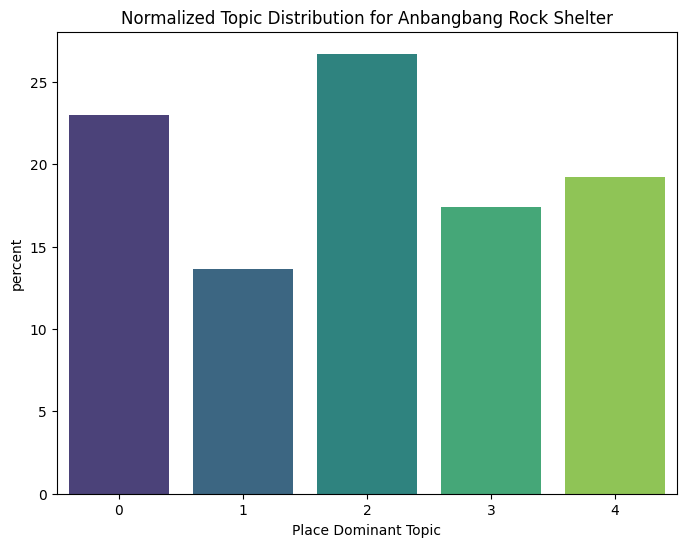

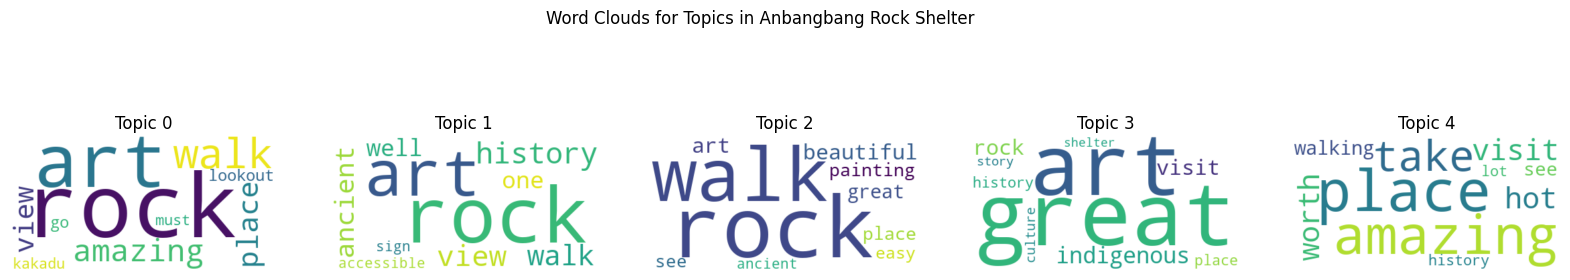


Place: Jim Jim Falls
Dominant Topics Table for Jim Jim Falls:
   Topic                                          Top Terms
0      0  road, today, walk, excellent, hour, done, corr...
1      1  place, fall, jim, spot, beautiful, flowing, se...
2      2  fall, water, last, place, worth, beautiful, dr...
3      3  jim, fall, park, way, car, early, view, pool, ...
4      4  walk, fall, get, absolutely, worth, pool, arou...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


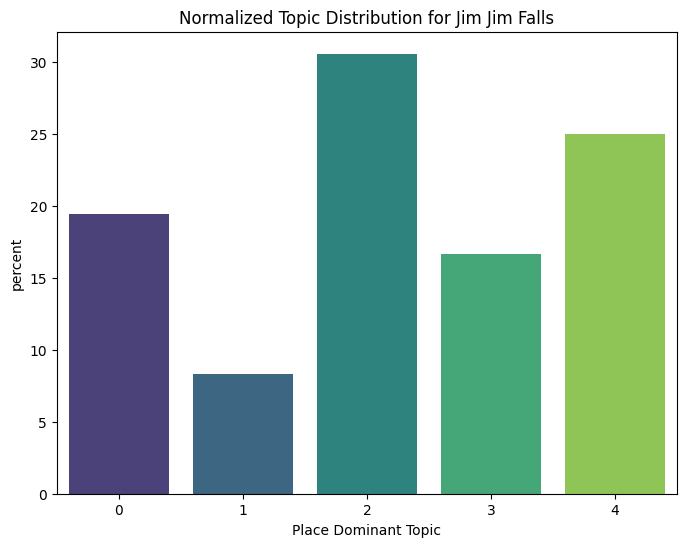

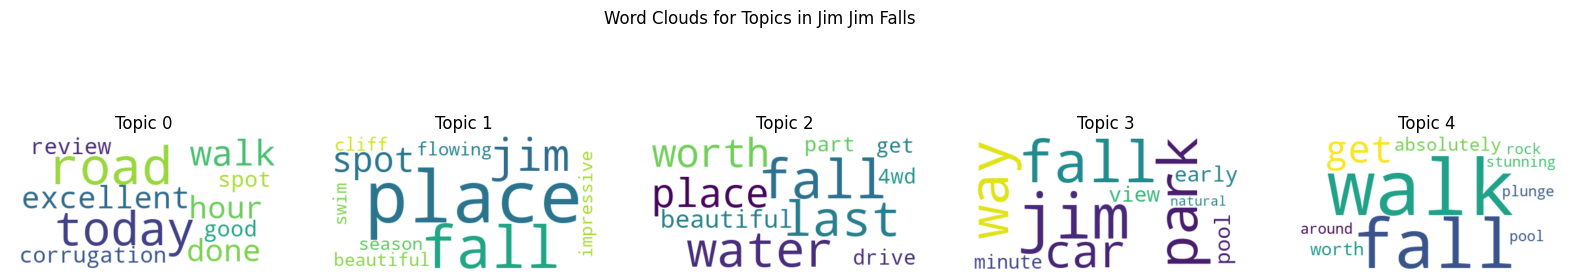


Place: Katherin hot springs
Dominant Topics Table for Katherin hot springs:
   Topic                                          Top Terms
0      0  water, hot, spring, nice, warm, spot, place, c...
1      1  place, beautiful, spring, hot, great, swim, wa...
2      2  water, place, lovely, pool, katherine, season,...
3      3  water, spring, great, spot, warm, hot, nice, b...
4      4  great, place, spot, busy, good, spring, nice, ...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


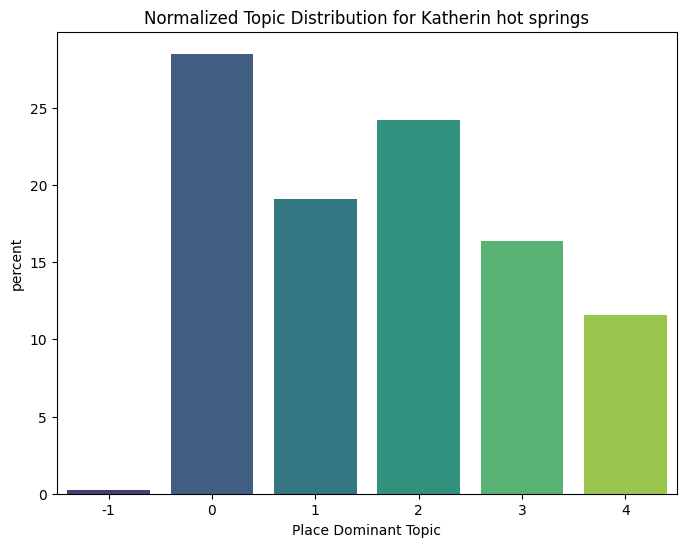

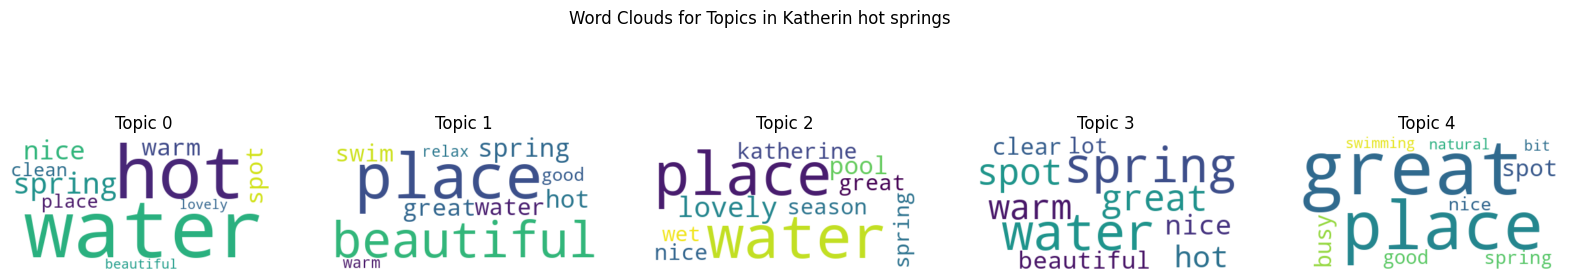


Place: Mataranka Thermal Pool and Rainbow Springs
Dominant Topics Table for Mataranka Thermal Pool and Rainbow Springs:
   Topic                                          Top Terms
0      0  great, place, pool, time, visit, busy, must, w...
1      1  pool, park, experience, beautiful, thermal, ba...
2      2  place, spring, beautiful, go, awesome, park, s...
3      3  water, beautiful, place, pool, clear, warm, sp...
4      4  spring, pool, thermal, place, relaxing, great,...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


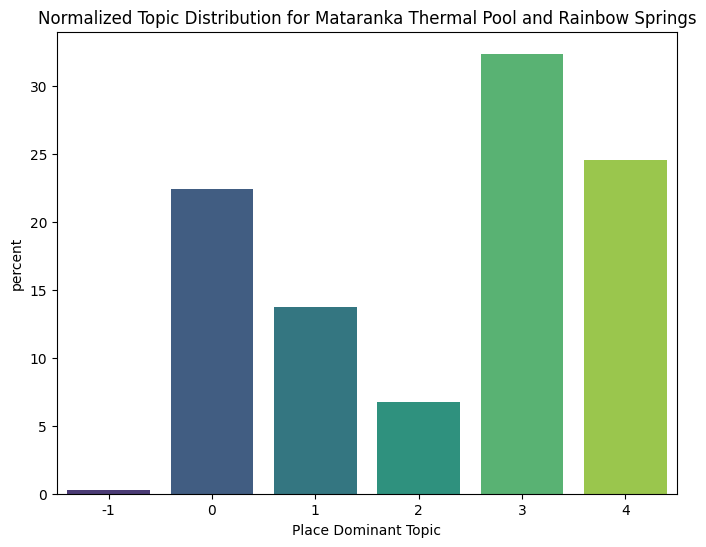

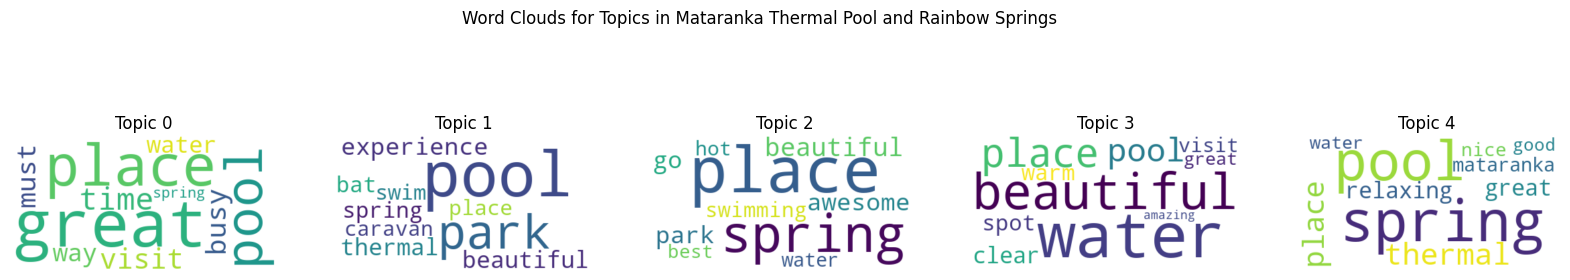


Place: Nitmiluk National Park
Dominant Topics Table for Nitmiluk National Park:
   Topic                                          Top Terms
0      0  good, great, tour, gorge, cruise, water, walk,...
1      1  beautiful, great, gorge, walk, experience, kat...
2      2  gorge, amazing, place, tour, wonderful, cruise...
3      3  place, great, visit, must, time, absolutely, s...
4      4  park, beautiful, water, gorge, tour, trail, on...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


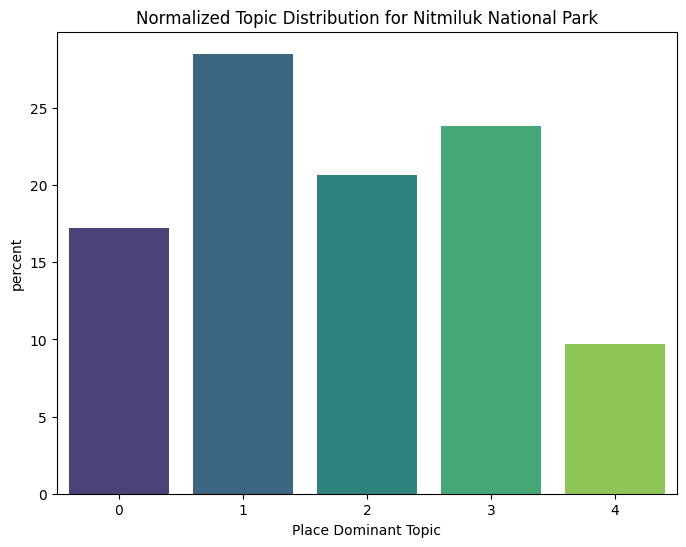

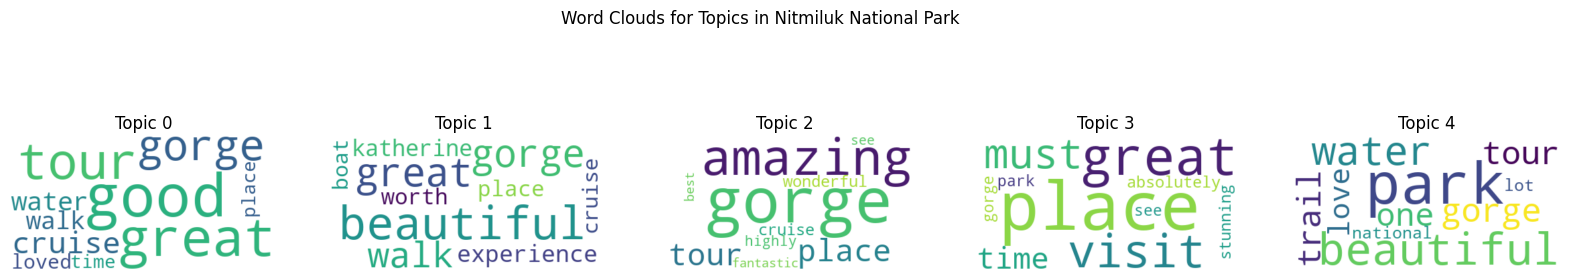


Place: Elsey National Park
Dominant Topics Table for Elsey National Park:
   Topic                                          Top Terms
0      0  beautiful, place, lovely, spot, visit, cool, g...
1      1  spring, thermal, pool, water, bitter, place, b...
2      2  great, loved, good, worth, place, walk, park, ...
3      3  good, place, great, facility, australia, see, ...
4      4  great, nice, spring, bitter, swimming, place, ...


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3184465184.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')


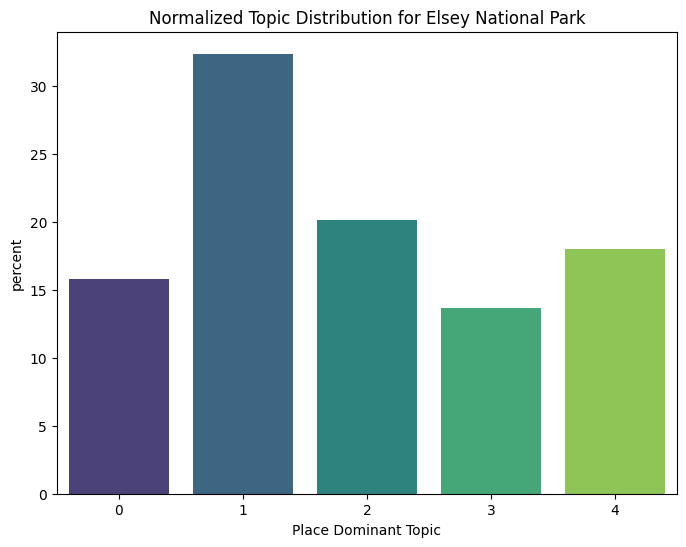

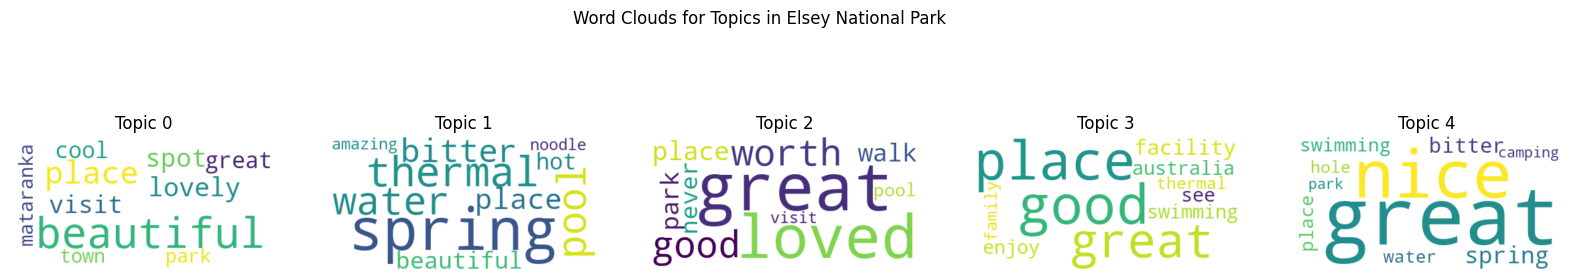

Topic modeling statistics exported to Output/google_topic_modelling.txt


In [7]:
# Part 2: Topic Modeling using LDA (Gensim) to Identify Key Themes for Tourism Growth
texts = [text.split() for text in df['Processed Review'] if text]
dictionary = corpora.Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]

lda_model = LdaModel(corpus, num_topics=5, id2word=dictionary, passes=15)

# Create table for dominant topics
topics_data = []
for idx, topic in lda_model.print_topics(5):
    terms = topic.split(' + ')
    topic_terms = ', '.join([t.split('*')[1].strip('"') for t in terms])
    topics_data.append({'Topic': idx, 'Top Terms': topic_terms})

topics_df = pd.DataFrame(topics_data)
print("Dominant Topics Table (Overall):")
print(topics_df)

# Assign dominant topics to reviews for segmentation
def get_dominant_topic(bow):
    topics = lda_model.get_document_topics(bow)
    return max(topics, key=lambda x: x[1])[0] if topics else -1

dominant_topics = []
for text in df['Processed Review']:
    if text:
        bow = dictionary.doc2bow(text.split())
        dominant_topics.append(get_dominant_topic(bow))
    else:
        dominant_topics.append(-1)

df['Dominant Topic'] = dominant_topics

# Visualize Topic Distribution - Identifies popular vs. underrepresented tourism aspects (normalized)
plt.figure(figsize=(8, 6))
sns.countplot(x='Dominant Topic', data=df, palette='viridis', stat='percent')
plt.title('Normalized Topic Distribution in Reviews - Opportunities for Tourism Product Development')
plt.show()

# Word Clouds for each topic in a grid - Visual aid for marketing and product ideas
fig, axs = plt.subplots(1, 5, figsize=(20, 4))
for topic_id, ax in enumerate(axs):
    terms = lda_model.show_topic(topic_id, 10)
    wordcloud = WordCloud(width=400, height=200, background_color='white').generate_from_frequencies(dict(terms))
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(f'Topic {topic_id}')
    ax.axis('off')
plt.suptitle('Word Clouds for Topics - Key Themes for Business Actions')
plt.show()

# Group by region for topic modeling
print("\nTopic Analysis Grouped by Region:")

for region in unique_regions:
    print(f"\nRegion: {region}")
    region_df = df[df['region'] == region]
    if len(region_df) < 10:  # Skip if too few reviews
        print("Insufficient data for topic modeling.")
        continue
    
    region_texts = [text.split() for text in region_df['Processed Review'] if text]
    if not region_texts:
        print("No processed reviews available.")
        continue
    
    region_dictionary = corpora.Dictionary(region_texts)
    region_corpus = [region_dictionary.doc2bow(text) for text in region_texts]
    
    region_lda_model = LdaModel(region_corpus, num_topics=5, id2word=region_dictionary, passes=15)
    
    # Create table for region topics
    region_topics_data = []
    for idx, topic in region_lda_model.print_topics(5):
        terms = topic.split(' + ')
        topic_terms = ', '.join([t.split('*')[1].strip('"') for t in terms])
        region_topics_data.append({'Topic': idx, 'Top Terms': topic_terms})
    
    region_topics_df = pd.DataFrame(region_topics_data)
    print(f"Dominant Topics Table for {region}:")
    print(region_topics_df)
    
    # Assign dominant topics
    def get_region_dominant_topic(bow):
        topics = region_lda_model.get_document_topics(bow)
        return max(topics, key=lambda x: x[1])[0] if topics else -1
    
    dominant_topics_region = []
    for text in region_df['Processed Review']:
        if text:
            bow = region_dictionary.doc2bow(text.split())
            dominant_topics_region.append(get_region_dominant_topic(bow))
        else:
            dominant_topics_region.append(-1)
    
    region_df = region_df.copy()  # Avoid SettingWithCopyWarning
    region_df['Region Dominant Topic'] = dominant_topics_region
    
    # Normalized Topic Distribution
    plt.figure(figsize=(8, 6))
    sns.countplot(x='Region Dominant Topic', data=region_df, palette='viridis', stat='percent')
    plt.title(f'Normalized Topic Distribution for {region}')
    plt.show()
    
    # Word Clouds in grid
    fig, axs = plt.subplots(1, 5, figsize=(20, 4))
    for topic_id, ax in enumerate(axs):
        terms = region_lda_model.show_topic(topic_id, 10)
        wordcloud = WordCloud(width=400, height=200, background_color='white').generate_from_frequencies(dict(terms))
        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title(f'Topic {topic_id}')
        ax.axis('off')
    plt.suptitle(f'Word Clouds for Topics in {region}')
    plt.show()

# Group by place for topic modeling
print("\nTopic Analysis Grouped by Place:")

unique_places = df['name_of_place'].unique()
for place in unique_places:
    print(f"\nPlace: {place}")
    place_df = df[df['name_of_place'] == place]
    if len(place_df) < 10:  # Skip if too few reviews
        print("Insufficient data for topic modeling.")
        continue
    
    place_texts = [text.split() for text in place_df['Processed Review'] if text]
    if not place_texts:
        print("No processed reviews available.")
        continue
    
    place_dictionary = corpora.Dictionary(place_texts)
    place_corpus = [place_dictionary.doc2bow(text) for text in place_texts]
    
    place_lda_model = LdaModel(place_corpus, num_topics=5, id2word=place_dictionary, passes=15)
    
    # Create table for place topics
    place_topics_data = []
    for idx, topic in place_lda_model.print_topics(5):
        terms = topic.split(' + ')
        topic_terms = ', '.join([t.split('*')[1].strip('"') for t in terms])
        place_topics_data.append({'Topic': idx, 'Top Terms': topic_terms})
    
    place_topics_df = pd.DataFrame(place_topics_data)
    print(f"Dominant Topics Table for {place}:")
    print(place_topics_df)
    
    # Assign dominant topics
    def get_place_dominant_topic(bow):
        topics = place_lda_model.get_document_topics(bow)
        return max(topics, key=lambda x: x[1])[0] if topics else -1
    
    dominant_topics_place = []
    for text in place_df['Processed Review']:
        if text:
            bow = place_dictionary.doc2bow(text.split())
            dominant_topics_place.append(get_place_dominant_topic(bow))
        else:
            dominant_topics_place.append(-1)
    
    place_df = place_df.copy()  # Avoid SettingWithCopyWarning
    place_df['Place Dominant Topic'] = dominant_topics_place
    
    # Normalized Topic Distribution
    plt.figure(figsize=(8, 6))
    sns.countplot(x='Place Dominant Topic', data=place_df, palette='viridis', stat='percent')
    plt.title(f'Normalized Topic Distribution for {place}')
    plt.show()
    
    # Word Clouds in grid
    fig, axs = plt.subplots(1, 5, figsize=(20, 4))
    for topic_id, ax in enumerate(axs):
        terms = place_lda_model.show_topic(topic_id, 10)
        wordcloud = WordCloud(width=400, height=200, background_color='white').generate_from_frequencies(dict(terms))
        ax.imshow(wordcloud, interpolation='bilinear')
        ax.set_title(f'Topic {topic_id}')
        ax.axis('off')
    plt.suptitle(f'Word Clouds for Topics in {place}')
    plt.show()



dictionary = corpora.Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]

lda_model = LdaModel(corpus, num_topics=5, id2word=dictionary, passes=15)

# Create Output directory if it doesn't exist
os.makedirs('Output', exist_ok=True)

# Export statistics to file
output_file = 'Output/google_topic_modelling.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write("Google Review Topic Modeling Statistics\n")
    f.write("=" * 50 + "\n\n")
    
    f.write("Dominant Topics (Overall):\n")
    topics_data = []
    for idx, topic in lda_model.print_topics(5):
        terms = topic.split(' + ')
        topic_terms = ', '.join([t.split('*')[1].strip('"') for t in terms])
        topics_data.append({'Topic': idx, 'Top Terms': topic_terms})
    topics_df = pd.DataFrame(topics_data)
    f.write(topics_df.to_string(index=False) + "\n\n")
    
    f.write("Topic Distribution (Overall):\n")
    dominant_topics = []
    for text in df['Processed Review']:
        if text:
            bow = dictionary.doc2bow(text.split())
            topics = lda_model.get_document_topics(bow)
            dominant_topic = max(topics, key=lambda x: x[1])[0] if topics else -1
            dominant_topics.append(dominant_topic)
        else:
            dominant_topics.append(-1)
    df['Dominant Topic'] = dominant_topics
    topic_counts = df['Dominant Topic'].value_counts(normalize=True) * 100
    for topic, percentage in topic_counts.items():
        f.write(f"Topic {topic}: {percentage:.2f}%\n")
    f.write("\n")
    
    f.write("Topic Analysis by Region:\n")
    unique_regions = df['region'].unique()
    for region in sorted(unique_regions):
        f.write(f"\nRegion: {region}\n")
        region_df = df[df['region'] == region]
        if len(region_df) < 10:
            f.write("Insufficient data for topic modeling.\n")
            continue
        
        region_texts = [text.split() for text in region_df['Processed Review'] if text]
        if not region_texts:
            f.write("No processed reviews available.\n")
            continue
        
        region_dictionary = corpora.Dictionary(region_texts)
        region_corpus = [region_dictionary.doc2bow(text) for text in region_texts]
        region_lda_model = LdaModel(region_corpus, num_topics=5, id2word=region_dictionary, passes=15)
        
        f.write(f"Dominant Topics Table for {region}:\n")
        region_topics_data = []
        for idx, topic in region_lda_model.print_topics(5):
            terms = topic.split(' + ')
            topic_terms = ', '.join([t.split('*')[1].strip('"') for t in terms])
            region_topics_data.append({'Topic': idx, 'Top Terms': topic_terms})
        region_topics_df = pd.DataFrame(region_topics_data)
        f.write(region_topics_df.to_string(index=False) + "\n")
        
        f.write(f"Topic Distribution for {region}:\n")
        dominant_topics_region = []
        for text in region_df['Processed Review']:
            if text:
                bow = region_dictionary.doc2bow(text.split())
                topics = region_lda_model.get_document_topics(bow)
                dominant_topic = max(topics, key=lambda x: x[1])[0] if topics else -1
                dominant_topics_region.append(dominant_topic)
            else:
                dominant_topics_region.append(-1)
        region_df = region_df.copy()
        region_df['Region Dominant Topic'] = dominant_topics_region
        region_topic_counts = region_df['Region Dominant Topic'].value_counts(normalize=True) * 100
        for topic, percentage in region_topic_counts.items():
            f.write(f"Topic {topic}: {percentage:.2f}%\n")
        f.write("\n")
    
    f.write("Topic Analysis by Place:\n")
    unique_places = df['name_of_place'].unique()
    for place in sorted(unique_places):
        f.write(f"\nPlace: {place}\n")
        place_df = df[df['name_of_place'] == place]
        if len(place_df) < 10:
            f.write("Insufficient data for topic modeling.\n")
            continue
        
        place_texts = [text.split() for text in place_df['Processed Review'] if text]
        if not place_texts:
            f.write("No processed reviews available.\n")
            continue
        
        place_dictionary = corpora.Dictionary(place_texts)
        place_corpus = [place_dictionary.doc2bow(text) for text in place_texts]
        place_lda_model = LdaModel(place_corpus, num_topics=5, id2word=place_dictionary, passes=15)
        
        f.write(f"Dominant Topics Table for {place}:\n")
        place_topics_data = []
        for idx, topic in place_lda_model.print_topics(5):
            terms = topic.split(' + ')
            topic_terms = ', '.join([t.split('*')[1].strip('"') for t in terms])
            place_topics_data.append({'Topic': idx, 'Top Terms': topic_terms})
        place_topics_df = pd.DataFrame(place_topics_data)
        f.write(place_topics_df.to_string(index=False) + "\n")
        
        f.write(f"Topic Distribution for {place}:\n")
        dominant_topics_place = []
        for text in place_df['Processed Review']:
            if text:
                bow = place_dictionary.doc2bow(text.split())
                topics = place_lda_model.get_document_topics(bow)
                dominant_topic = max(topics, key=lambda x: x[1])[0] if topics else -1
                dominant_topics_place.append(dominant_topic)
            else:
                dominant_topics_place.append(-1)
        place_df = place_df.copy()
        place_df['Place Dominant Topic'] = dominant_topics_place
        place_topic_counts = place_df['Place Dominant Topic'].value_counts(normalize=True) * 100
        for topic, percentage in place_topic_counts.items():
            f.write(f"Topic {topic}: {percentage:.2f}%\n")
        f.write("\n")

print(f"Topic modeling statistics exported to {output_file}")


    

/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


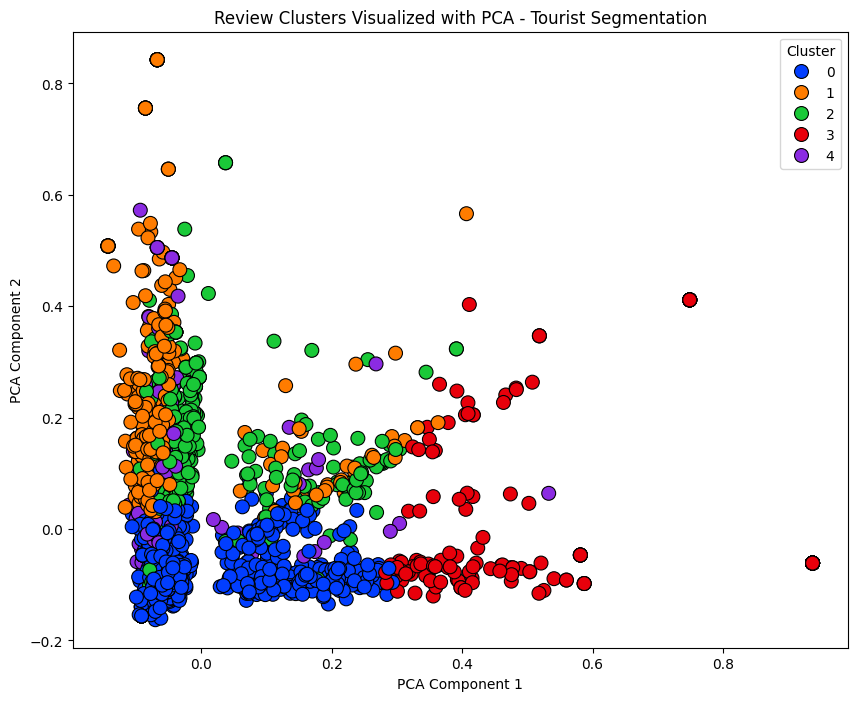

Cluster 0 Top Terms (Potential Segment): area, pool, spring, beautiful, park, rock, walk, nice, water, good
Cluster 1 Top Terms (Potential Segment): restaurant, beautiful, walk, swimming, visit, pool, swim, spot, place, great
Cluster 2 Top Terms (Potential Segment): best, lovely, worth, go, beautiful, nice, see, must, visit, place
Cluster 3 Top Terms (Potential Segment): water, absolutely, view, swimming, swim, spring, park, spot, place, beautiful
Cluster 4 Top Terms (Potential Segment): beautiful, water, rock, scenery, absolutely, walk, experience, visit, place, amazing

Clustering Analysis Grouped by Region:

Region: Darwin Region


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  region_df['Region Cluster'] = region_kmeans.fit_predict(region_X)


Cluster 0 Top Terms: waterfall, darwin, day, pool, park, good, water, lovely, amazing, swimming
Cluster 1 Top Terms: water, relax, best, worth, darwin, amazing, love, swim, visit, place
Cluster 2 Top Terms: clear, view, park, waterfall, swim, water, swimming, spot, place, beautiful
Cluster 3 Top Terms: shop, cool, food, walk, restaurant, swim, area, water, place, nice
Cluster 4 Top Terms: family, pool, swimming, swim, spot, food, restaurant, area, place, great

Region: Alice Spring Region


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  region_df['Region Cluster'] = region_kmeans.fit_predict(region_X)


Cluster 0 Top Terms: gorge, view, scenery, hike, worth, visit, experience, walk, place, amazing
Cluster 1 Top Terms: landscape, loved, scenery, spot, experience, visit, walk, view, place, great
Cluster 2 Top Terms: magical, experience, walk, worth, good, visit, nice, uluru, rock, place
Cluster 3 Top Terms: worth, park, absolutely, look, spot, peaceful, visit, recommended, place, beautiful
Cluster 4 Top Terms: area, australia, walk, go, awesome, beautiful, place, visit, see, must

Region: Kakadu Regional


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  region_df['Region Cluster'] = region_kmeans.fit_predict(region_X)


Cluster 0 Top Terms: wonderful, time, experience, trip, day, worth, place, amazing, great, see
Cluster 1 Top Terms: see, view, painting, aboriginal, amazing, easy, great, walk, art, rock
Cluster 2 Top Terms: jim, bird, area, australia, many, one, closed, national, kakadu, park
Cluster 3 Top Terms: go, historical, kakadu, best, one, must, great, amazing, visit, place
Cluster 4 Top Terms: magic, tour, people, scenery, lot, national, wonderful, park, place, beautiful

Region: Katherin


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  region_df['Region Cluster'] = region_kmeans.fit_predict(region_X)


Cluster 0 Top Terms: walk, spot, hot, area, water, place, spring, thermal, pool, lovely
Cluster 1 Top Terms: surroundings, natural, hot, water, great, guide, place, spring, spot, beautiful
Cluster 2 Top Terms: clean, spot, hot, spring, place, crystal, warm, clear, water, nice
Cluster 3 Top Terms: loved, awesome, must, worth, gorge, spring, visit, amazing, place, good
Cluster 4 Top Terms: spring, time, swimming, thermal, visit, pool, swim, spot, place, great


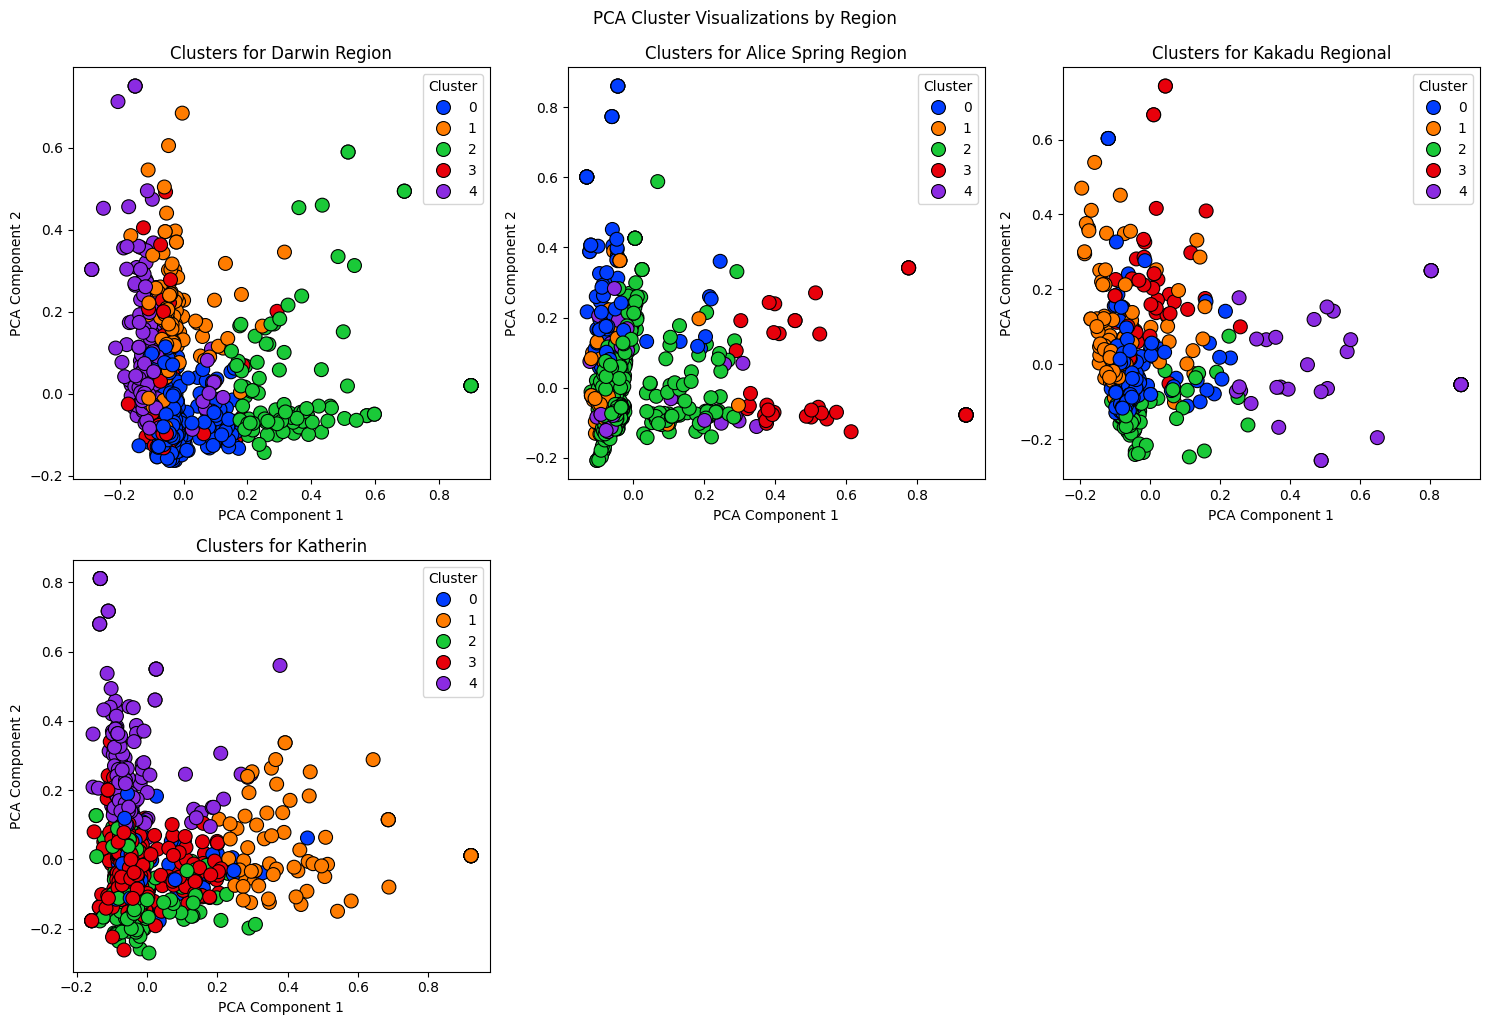


Clustering Analysis Grouped by Place:

Place: Berry Springs Nature Park


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:96: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  place_df['Place Cluster'] = place_kmeans.fit_predict(place_X)


Cluster 0 Top Terms: waterfall, season, due, darwin, water, great, spring, best, hole, swimming
Cluster 0 Top Terms: waterfall, season, due, darwin, water, great, spring, best, hole, swimming
Cluster 1 Top Terms: spot, great, warm, picnic, area, park, lovely, spring, pool, water
Cluster 1 Top Terms: spot, great, warm, picnic, area, park, lovely, spring, pool, water
Cluster 2 Top Terms: spot, cool, lovely, relax, warm, water, nice, great, place, swim
Cluster 2 Top Terms: spot, cool, lovely, relax, warm, water, nice, great, place, swim
Cluster 3 Top Terms: natural, dip, temperature, pool, clear, swimming, water, place, spot, beautiful
Cluster 3 Top Terms: natural, dip, temperature, pool, clear, swimming, water, place, spot, beautiful
Cluster 4 Top Terms: room, easy, absolutely, crowd, place, perfect, day, early, busy, get
Cluster 4 Top Terms: room, easy, absolutely, crowd, place, perfect, day, early, busy, get

Place: Litchfield National Park


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:96: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  place_df['Place Cluster'] = place_kmeans.fit_predict(place_X)


Cluster 0 Top Terms: darwin, better, lot, best, see, time, worth, awesome, nice, day
Cluster 0 Top Terms: darwin, better, lot, best, see, time, worth, awesome, nice, day
Cluster 1 Top Terms: nt, many, worth, fantastic, darwin, great, love, amazing, visit, place
Cluster 1 Top Terms: nt, many, worth, fantastic, darwin, great, love, amazing, visit, place
Cluster 2 Top Terms: walking, place, park, water, beautiful, great, waterfall, hole, amazing, swimming
Cluster 2 Top Terms: walking, place, park, water, beautiful, great, waterfall, hole, amazing, swimming
Cluster 3 Top Terms: trip, well, love, amazing, waterfall, view, country, park, place, beautiful
Cluster 3 Top Terms: trip, well, love, amazing, waterfall, view, country, park, place, beautiful
Cluster 4 Top Terms: walk, place, easy, florence, wangi, national, great, swim, park, fall
Cluster 4 Top Terms: walk, place, easy, florence, wangi, national, great, swim, park, fall

Place: Darwin Waterfront Precinct


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:96: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  place_df['Place Cluster'] = place_kmeans.fit_predict(place_X)


... (10 outputs left out)

Cluster 0 Top Terms: park, lovely, busy, bat, loved, good, visit, place, spot, beautiful
Cluster 0 Top Terms: park, lovely, busy, bat, loved, good, visit, place, spot, beautiful
Cluster 1 Top Terms: spring, temperature, pool, beautiful, place, crystal, warm, amazing, clear, water
Cluster 1 Top Terms: spring, temperature, pool, beautiful, place, crystal, warm, amazing, clear, water
Cluster 2 Top Terms: swim, time, bit, beautiful, pool, relax, visit, spot, place, great
Cluster 2 Top Terms: swim, time, bit, beautiful, pool, relax, visit, spot, place, great
Cluster 3 Top Terms: swimming, mataranka, bitter, swim, hot, place, relaxing, spring, thermal, pool
Cluster 3 Top Terms: swimming, mataranka, bitter, swim, hot, place, relaxing, spring, thermal, pool
Cluster 4 Top Terms: swimming, dip, spot, bat, spring, place, swim, warm, crowded, nice
Cluster 4 Top Terms: swimming, dip, spot, bat, spring, place, swim, warm, crowded, nice

Place: Nitmiluk National Park


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:96: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  place_df['Place Cluster'] = place_kmeans.fit_predict(place_X)


Cluster 0 Top Terms: well, special, spot, guide, lovely, worth, fall, experience, place, beautiful
Cluster 0 Top Terms: well, special, spot, guide, lovely, worth, fall, experience, place, beautiful
Cluster 1 Top Terms: stunning, absolutely, visit, walk, nice, experience, fantastic, awesome, good, place
Cluster 1 Top Terms: stunning, absolutely, visit, walk, nice, experience, fantastic, awesome, good, place
Cluster 2 Top Terms: colour, scenery, cruise, tour, visit, guide, boat, gorge, place, amazing
Cluster 2 Top Terms: colour, scenery, cruise, tour, visit, guide, boat, gorge, place, amazing
Cluster 3 Top Terms: wonderful, park, highly, boat, must, worth, cruise, tour, see, gorge
Cluster 3 Top Terms: wonderful, park, highly, boat, must, worth, cruise, tour, see, gorge
Cluster 4 Top Terms: spot, scenery, katherine, trip, beautiful, gorge, cruise, guide, place, great
Cluster 4 Top Terms: spot, scenery, katherine, trip, beautiful, gorge, cruise, guide, place, great

Place: Elsey National P

/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_21766/3763416123.py:96: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  place_df['Place Cluster'] = place_kmeans.fit_predict(place_X)


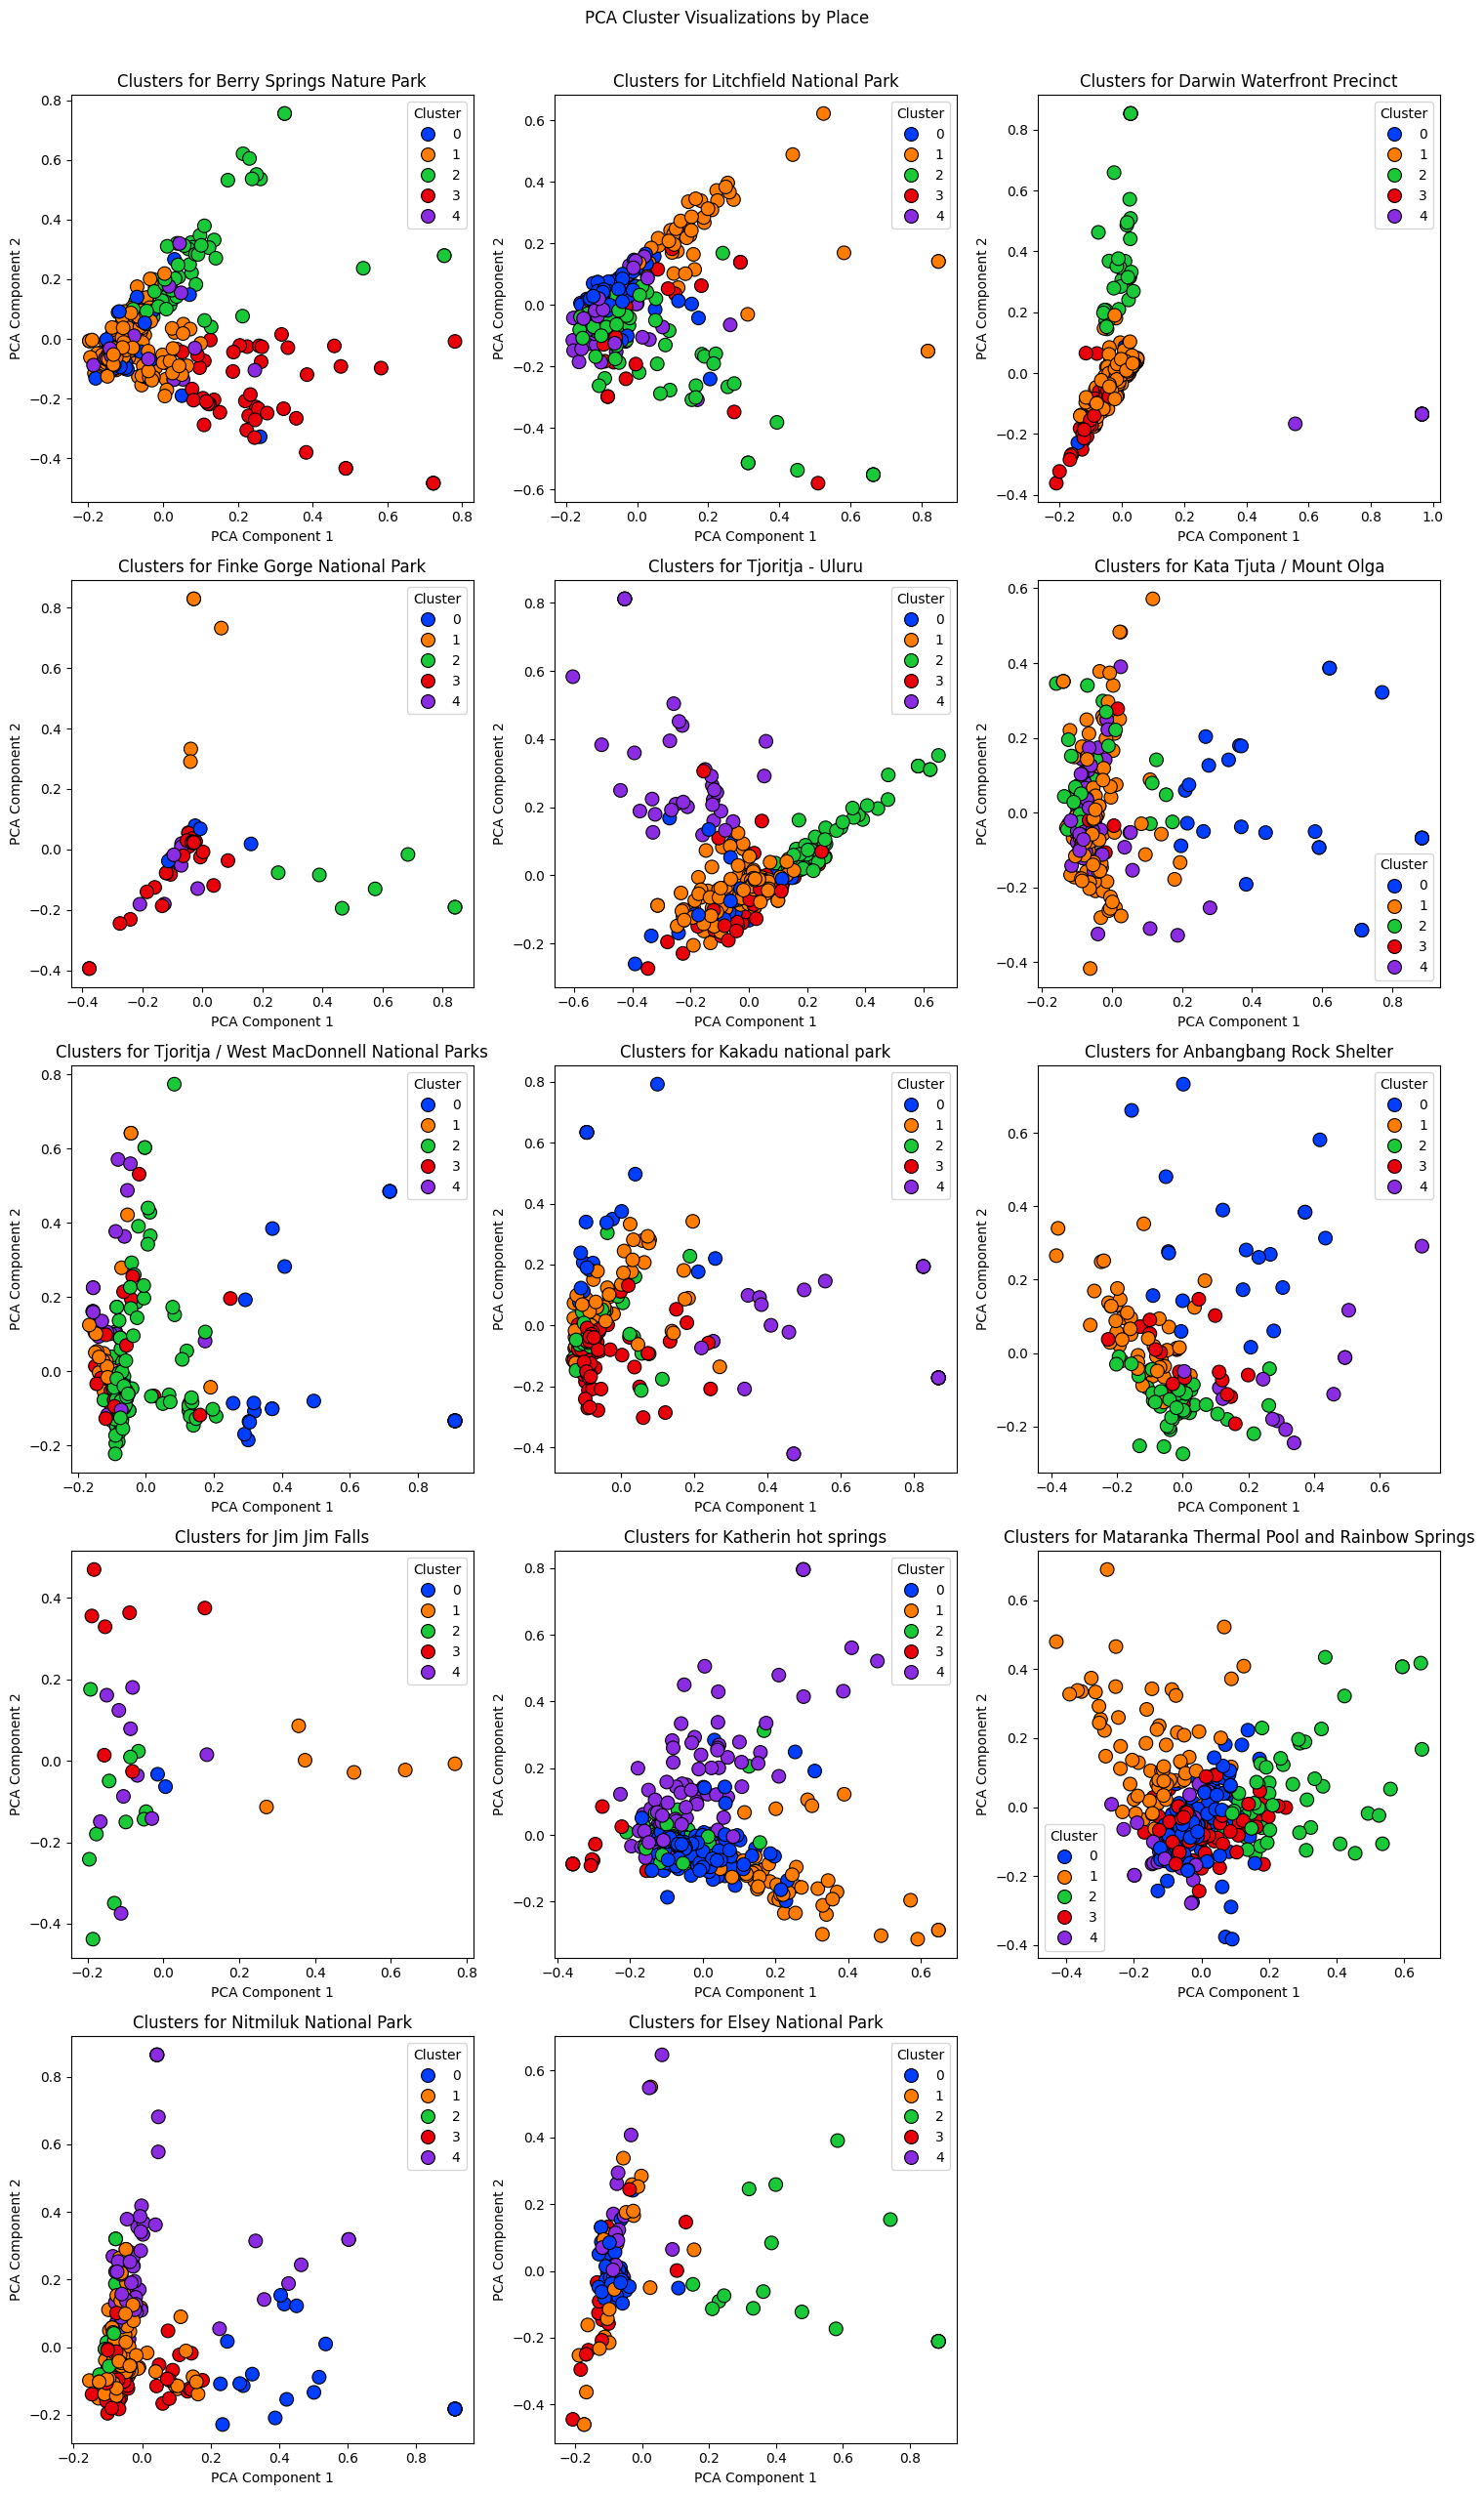

/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_

Clustering statistics exported to Output/google_clustering.txt


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


In [9]:
# Part 3: Clustering Reviews using KMeans on TF-IDF for Customer Segmentation
vectorizer = TfidfVectorizer(max_features=500)
X = vectorizer.fit_transform(df['Processed Review'])

kmeans = KMeans(n_clusters=5, random_state=42)
df['Cluster'] = kmeans.fit_predict(X)

# Visualize Clusters with PCA - Segments tourists for targeted marketing
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(10, 8))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['Cluster'], palette='bright', s=100, edgecolor='k')
plt.title('Review Clusters Visualized with PCA - Tourist Segmentation')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster', loc='best')
plt.show()

# Prove Clusters: Top terms per cluster to label
feature_names = vectorizer.get_feature_names_out()
for i in range(5):
    center = kmeans.cluster_centers_[i]
    top_terms = [feature_names[idx] for idx in center.argsort()[-10:]]
    print(f"Cluster {i} Top Terms (Potential Segment): {', '.join(top_terms)}")

# Group by region for clustering
print("\nClustering Analysis Grouped by Region:")

num_regions = len(unique_regions)
rows = (num_regions + 2) // 3  # For 3 columns grid
fig, axs = plt.subplots(rows, 3, figsize=(15, 5 * rows))
axs = axs.flatten()

for idx, region in enumerate(unique_regions):
    print(f"\nRegion: {region}")
    region_df = df[df['region'] == region]
    if len(region_df) < 10:
        print("Insufficient data for clustering.")
        continue
    
    region_vectorizer = TfidfVectorizer(max_features=500)
    region_X = region_vectorizer.fit_transform(region_df['Processed Review'])
    if region_X.shape[0] < 5:  # Need at least 5 samples for 5 clusters
        print("Insufficient data for 5 clusters.")
        continue
    
    region_kmeans = KMeans(n_clusters=5, random_state=42)
    region_df['Region Cluster'] = region_kmeans.fit_predict(region_X)
    
    region_pca = PCA(n_components=2)
    region_X_pca = region_pca.fit_transform(region_X.toarray())
    
    sns.scatterplot(x=region_X_pca[:, 0], y=region_X_pca[:, 1], hue=region_df['Region Cluster'], palette='bright', s=100, edgecolor='k', ax=axs[idx])
    axs[idx].set_title(f'Clusters for {region}')
    axs[idx].set_xlabel('PCA Component 1')
    axs[idx].set_ylabel('PCA Component 2')
    axs[idx].legend(title='Cluster', loc='best')
    
    # Top terms
    region_feature_names = region_vectorizer.get_feature_names_out()
    for i in range(5):
        center = region_kmeans.cluster_centers_[i]
        top_terms = [region_feature_names[idx] for idx in center.argsort()[-10:]]
        print(f"Cluster {i} Top Terms: {', '.join(top_terms)}")

# Hide unused subplots
for j in range(idx + 1, len(axs)):
    axs[j].axis('off')

plt.tight_layout()
plt.suptitle('PCA Cluster Visualizations by Region', y=1.02)
plt.show()

# Group by place for clustering
print("\nClustering Analysis Grouped by Place:")

num_places = len(unique_places)
rows = (num_places + 2) // 3  # For 3 columns grid
fig, axs = plt.subplots(rows, 3, figsize=(15, 5 * rows))
axs = axs.flatten()
for idx, place in enumerate(unique_places):
    print(f"\nPlace: {place}")
    place_df = df[df['name_of_place'] == place]
    if len(place_df) < 10:
        print("Insufficient data for clustering.")
        continue
    
    place_vectorizer = TfidfVectorizer(max_features=500)
    place_X = place_vectorizer.fit_transform(place_df['Processed Review'])
    if place_X.shape[0] < 5:
        print("Insufficient data for 5 clusters.")
        continue
    
    place_kmeans = KMeans(n_clusters=5, random_state=42)
    place_df['Place Cluster'] = place_kmeans.fit_predict(place_X)
    
    place_pca = PCA(n_components=2)
    place_X_pca = place_pca.fit_transform(place_X.toarray())
    
    sns.scatterplot(x=place_X_pca[:, 0], y=place_X_pca[:, 1], hue=place_df['Place Cluster'], palette='bright', s=100, edgecolor='k', ax=axs[idx])
    axs[idx].set_title(f'Clusters for {place}')
    axs[idx].set_xlabel('PCA Component 1')
    axs[idx].set_ylabel('PCA Component 2')
    axs[idx].legend(title='Cluster', loc='best')
    
    # Top terms
    place_feature_names = place_vectorizer.get_feature_names_out()
    for i in range(5):
        center = place_kmeans.cluster_centers_[i]
        top_terms = [place_feature_names[idx] for idx in center.argsort()[-10:]]
        print(f"Cluster {i} Top Terms: {', '.join(top_terms)}")
        print(f"Cluster {i} Top Terms: {', '.join(top_terms)}")

# Hide unused subplots
for j in range(idx + 1, len(axs)):
    axs[j].axis('off')

plt.tight_layout()
plt.suptitle('PCA Cluster Visualizations by Place', y=1.02)
plt.show()



# Create Output directory if it doesn't exist
os.makedirs('Output', exist_ok=True)

# Export statistics to file
output_file = 'Output/google_clustering.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write("Google Review Clustering Statistics\n")
    f.write("=" * 50 + "\n\n")
    
    f.write("Clustering Analysis (Overall):\n")
    f.write(f"Number of Clusters: 5\n")
    f.write("Cluster Distribution (Overall):\n")
    cluster_counts = df['Cluster'].value_counts(normalize=True) * 100
    for cluster, percentage in cluster_counts.items():
        f.write(f"Cluster {cluster}: {percentage:.2f}%\n")
    f.write("\n")
    
    f.write("Top Terms per Cluster (Overall):\n")
    feature_names = vectorizer.get_feature_names_out()
    for i in range(5):
        center = kmeans.cluster_centers_[i]
        top_terms = [feature_names[idx] for idx in center.argsort()[-10:]]
        f.write(f"Cluster {i} Top Terms: {', '.join(top_terms)}\n")
    f.write("\n")
    
    f.write("Clustering Analysis by Region:\n")
    for region in sorted(unique_regions):
        f.write(f"\nRegion: {region}\n")
        region_df = df[df['region'] == region]
        if len(region_df) < 10:
            f.write("Insufficient data for clustering.\n")
            continue
        
        region_X = vectorizer.fit_transform(region_df['Processed Review'])
        if region_X.shape[0] < 5:
            f.write("Insufficient data for 5 clusters.\n")
            continue
        
        region_kmeans = KMeans(n_clusters=5, random_state=42)
        region_df = region_df.copy()
        region_df['Region Cluster'] = region_kmeans.fit_predict(region_X)
        
        f.write(f"Cluster Distribution for {region}:\n")
        region_cluster_counts = region_df['Region Cluster'].value_counts(normalize=True) * 100
        for cluster, percentage in region_cluster_counts.items():
            f.write(f"Cluster {cluster}: {percentage:.2f}%\n")
        
        f.write(f"Top Terms per Cluster for {region}:\n")
        region_feature_names = vectorizer.get_feature_names_out()
        for i in range(5):
            center = region_kmeans.cluster_centers_[i]
            top_terms = [region_feature_names[idx] for idx in center.argsort()[-10:]]
            f.write(f"Cluster {i} Top Terms: {', '.join(top_terms)}\n")
        f.write("\n")
    
    f.write("Clustering Analysis by Place:\n")
    for place in sorted(unique_places):
        f.write(f"\nPlace: {place}\n")
        place_df = df[df['name_of_place'] == place]
        if len(place_df) < 10:
            f.write("Insufficient data for clustering.\n")
            continue
        
        place_X = vectorizer.fit_transform(place_df['Processed Review'])
        if place_X.shape[0] < 5:
            f.write("Insufficient data for 5 clusters.\n")
            continue
        
        place_kmeans = KMeans(n_clusters=5, random_state=42)
        place_df = place_df.copy()
        place_df['Place Cluster'] = place_kmeans.fit_predict(place_X)
        
        f.write(f"Cluster Distribution for {place}:\n")
        place_cluster_counts = place_df['Place Cluster'].value_counts(normalize=True) * 100
        for cluster, percentage in place_cluster_counts.items():
            f.write(f"Cluster {cluster}: {percentage:.2f}%\n")
        
        f.write(f"Top Terms per Cluster for {place}:\n")
        place_feature_names = vectorizer.get_feature_names_out()
        for i in range(5):
            center = place_kmeans.cluster_centers_[i]
            top_terms = [place_feature_names[idx] for idx in center.argsort()[-10:]]
            f.write(f"Cluster {i} Top Terms: {', '.join(top_terms)}\n")
        f.write("\n")

print(f"Clustering statistics exported to {output_file}")

# Recommendations for NT Tourism Growth by Region

Based on:  
- **Sentiment Analysis:** 87% positive overall (positives: *beautiful, great, amazing*; negatives: *closed, crowds, season*).  
- **Topic Modeling:** Themes around *water/pools, walks, rocks/culture*.  
- **Clustering:** Segments like *adventure seekers* vs. *relaxation-focused*.  

These recommendations align with **NT Strategy 2030** (7% annual growth to $3.1B by 2030, regional dispersal) and **Drive Strategy achievements** (infrastructure upgrades; 704k drive visitors in 2022). They also consider workforce challenges (Accommodation snapshot: high turnover, skills shortages), emphasizing sustainable and culturally sensitive growth.

**Priority Areas:**  
- Infrastructure (fix “accessibility/closed” negatives)  
- Marketing (leverage positives like *scenery*)  
- Partnerships (e.g., Indigenous-led experiences)  

Baseline: **2022: 704k visitors, $1.23B spend**  
Projection model: **7% base growth + 5–10% enhancement** from actions.

---

## Darwin Region (Berry Springs, Litchfield, Waterfront)

**Key Insights:**  
- Strong positives: *water, swim, beautiful*.  
- Negatives: crowds, seasonal limits.  
- Workforce: 72% based here; high turnover (39% part-time).  
- Topics: parks/pools dominant.  

**Recommendations:**  
- *Businesses:* Develop family-oriented packages (Berry Springs + Litchfield hikes); partner with locals for eco-tours to reduce crowd complaints.  
- *Government:* Invest in seasonal infrastructure (shaded areas, fly nets) with $88M+ budgets; subsidize domestic entry to improve value perception.  

**Predicted Impact (2026):**  
- Visitors: **250k–265k** (5–10% uplift)  
- Spend: **$490M–$515M**  
- Jobs: **+200–400** (focus on full-time via apprenticeships in cooking/hospitality)  

---

## Alice Springs Region (Finke Gorge, Uluru, Kata Tjuta, West MacDonnell)

**Key Insights:**  
- Positives: *amazing, rock, walk* (cultural/adventure).  
- Negatives: flies, costs.  
- Topics: spiritual/rock themes.  
- Workforce: 15% share; skills gaps in customer service.  

**Recommendations:**  
- *Businesses:* Indigenous-led sunset tours (*Uluru, rock*) with affordable add-ons; segment clusters (helicopter views for high-yield adventure seekers).  
- *Government:* Subsidize fees/transport (address “costs” negatives); enhance digital bookings (Drive Strategy) for remote sites like Finke Gorge.  

**Predicted Impact (2026):**  
- Visitors: **150k–165k**  
- Spend: **$230M–$250M**  
- Jobs: **+150–300** (train in leadership/problem-solving to reduce turnover)  

---

## Kakadu Region (Kakadu Park, Anbangbang, Jim Jim Falls)

**Key Insights:**  
- Positives: *art, rock, beautiful*.  
- Negatives: “closed, season” (wet season access).  
- Clusters: wildlife/adventure focus.  
- Workforce: 9% share; FIFO (fly-in/fly-out) challenges.  

**Recommendations:**  
- *Businesses:* Dry-season boat tours (*Kakadu, art*); cultural partnerships at Anbangbang to attract *nature lovers*.  
- *Government:* Accelerate road upgrades (Kakadu access, Report Card); promote off-season alternatives to reduce “closed” complaints.  

**Predicted Impact (2026):**  
- Visitors: **120k–135k**  
- Spend: **$180M–$195M**  
- Jobs: **+100–200** (digital skills focus for bookings)  

---

## Katherine Region (Hot Springs, Mataranka Pool, Nitmiluk, Elsey Park)

**Key Insights:**  
- Positives: *water, pool, spring*.  
- Negatives: heat, seasonal issues.  
- Clusters: relaxation-focused.  
- Workforce: 5% share; relocation costs noted.  

**Recommendations:**  
- *Businesses:* Bundle thermal pool experiences with Nitmiluk gorge cruises; family-targeted shaded/swim packages.  
- *Government:* Improve amenities (rest facilities, Drive Strategy); fund Indigenous guides for cultural depth in springs/parks.  

**Predicted Impact (2026):**  
- Visitors: **260k–280k**  
- Spend: **$290M–$310M**  
- Jobs: **+150–300** (apprenticeships in cooking to fill skill gaps)  

---

## Overall Impact (2026)

- **Additional GSP:** **+$150M–$300M**  
- **Jobs Created:** **+600–1,200**  

Aligned with **Strategy 2030 pillars** (infrastructure, partnerships).  
Progress to be monitored via **annual report cards**.  


# Sentiment Analysis–Driven Impact Model

Based on the sentiment analysis of **3,806 reviews** (average compound score: **0.56**, with **87% positive**, **5% negative**, **8% neutral**), combined with baselines from key documents (e.g., **704,000 drive visitors** and **$1.233B drive expenditure in 2022** from the *Drive Strategy Report Card*, plus **8,100 jobs** from the *Accommodation Snapshot*), we modeled the potential impact of implementing the recommendations.

---

## Key Assumptions

- **Baseline Growth:**  
  NT Tourism Strategy 2030 targets ~7% annual growth to reach $3.1B by 2030 (from ~$2.1B pre-COVID baseline, adjusted to 2022 recovery figures).

- **Sentiment-Driven Enhancement:**  
  Addressing negatives (e.g., high costs, accessibility issues, themes like *crowds, flies, entry fees*) could lift sentiment by **10–20%**, translating to **5–10% additional growth**.  
  *(Benchmarked from QLD reforms: 1% satisfaction uplift = ~$10–20M spend increase.)*

- **Themes for Impact:**  
  Positives dominate (e.g., *beautiful, great, amazing*), but negatives (e.g., *closed, crowds, flies*) in Kakadu/Katherine suggest infrastructure fixes could improve dispersal and length of stay.

- **Economic Links:**  
  - Drive visitors contribute ~57% of tourism GSP (*Drive Strategy*).  
  - Jobs: 5.1% sector share (*Accommodation Snapshot*).  

---

## Projections (2026 – One Year Ahead)

- **Visitors:**  
  **788,480 – 823,680** (5–10% enhanced over 2022 baseline of 704,000 drive visitors).  

- **Expenditure:**  
  **$1,381M – $1,443M** (uplift from 2022’s $1.233B).  
  Proportional regional growth assumed, e.g.:  
  - Darwin: $438M → higher uplift  
  - Lasseter: $200M → cultural/tourism growth  

- **New Jobs Created:**  
  **~400–800** (based on 5.1% workforce share; 5% visitor growth = ~400 new roles in accommodation/food, aligned with the 8,100 baseline).  

---

## Rationale

- Aligns with **Strategy pillars**, e.g., infrastructure upgrades (road sealing in *Report Card*).  
- Reducing negatives by **50%** (via subsidies, improved access) could add **5–10%** beyond baseline 7% growth.  
- Regional breakdown:  
  - **Alice Springs:** High positives (*Uluru, rock*) → potential **15% uplift**.  
  - **Katherine:** Negatives on *season, closures* → **5–8% uplift** with interventions.  

---

## Visual Projection (Growth Trajectory)

*(Illustrative line chart – not included here)*  
- **Base Growth Line:** 704k in 2022 → ~920k by 2026.  
- **Enhanced Low:** 788k.  
- **Enhanced High:** 824k.  
- **X-axis:** Years (2022–2026).  
- **Y-axis:** Visitors.  
